# Actividad 3 — Chatbot bancario con Rasa: reglas vs. LLM

Este notebook acompaña al reporte de la actividad. Contiene el **código completo** de las dos versiones del chatbot bancario y su **ejecución**: levanta ambos bots, los prueba con las mismas frases y conversaciones, y compara los resultados. Incluye las pruebas comparativas de la **Fase 4** (sección 10), el análisis de la **Fase 5** (11) y la conclusión de la **Fase 6** (12).

| Versión | Carpeta | Cómo genera la respuesta |
|---|---|---|
| Sin LLM (Fase 2) | `chatbot-sin-llm/` | Respuestas fijas (`utter_*`) y plantillas en acciones personalizadas |
| Con LLM (Fase 3) | `chatbot-con-llm/` | Prompt con intención + consulta + contexto, enviado a `llama3.2` vía Ollama |

**Requisitos para ejecutarlo**

- Cada proyecto con su entorno `.venv` (Python 3.10 + Rasa 3.6), ya entrenado o listo para entrenarse.
- [Ollama](https://ollama.com) corriendo en `http://localhost:11434` con el modelo `llama3.2`.
- Este notebook corre en un kernel aparte (Python 3.12 con `pandas`, `matplotlib`, `requests` y `pyyaml`). Rasa no se importa aquí: cada bot se ejecuta como proceso con el Python de **su propio** proyecto y el notebook se comunica con él por HTTP.

> No está pensado para Google Colab: Rasa 3.6 requiere Python ≤ 3.10 y la versión con LLM necesita Ollama en la misma máquina.

In [1]:
# === Librerías ===
import atexit
import difflib
import html
import json
import os
import subprocess
import tempfile
import time
import unicodedata
import uuid
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
import yaml
from IPython.display import HTML, Code, Markdown, display

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

In [2]:
# === Proyectos, puertos y configuración general ===
BASE = Path.cwd()
RESULTADOS = BASE / "resultados"
RESULTADOS.mkdir(exist_ok=True)

# Se usa 127.0.0.1 y no "localhost": en Windows "localhost" se resuelve primero
# a ::1 (IPv6) y, como Rasa y Ollama escuchan solo en IPv4, cada conexión
# espera ~2 s antes de reintentar por IPv4 (se mide en la sección 4).
HOST = "127.0.0.1"
OLLAMA_URL = f"http://{HOST}:11434"
OLLAMA_MODEL = "llama3.2"

# Puertos distintos a los de `rasa shell` (5005 / 5055) para no chocar con
# una sesión que esté abierta en otra terminal.
PROYECTOS = {
    "Sin LLM": {"carpeta": BASE / "chatbot-sin-llm", "puerto_rasa": 5105, "puerto_acciones": 5155},
    "Con LLM": {"carpeta": BASE / "chatbot-con-llm", "puerto_rasa": 5205, "puerto_acciones": 5255},
}

for nombre, p in PROYECTOS.items():
    bin_dir = "Scripts/python.exe" if os.name == "nt" else "bin/python"
    p["python"] = p["carpeta"] / ".venv" / bin_dir
    p["url"] = f"http://{HOST}:{p['puerto_rasa']}"
    p["url_acciones"] = f"http://{HOST}:{p['puerto_acciones']}"

# Variables de entorno para los procesos de Rasa. actions.py lee OLLAMA_URL y
# OLLAMA_MODEL con os.getenv, así que no hace falta modificar el proyecto.
ENV = os.environ.copy()
ENV.update({
    "PYTHONIOENCODING": "utf-8",
    "OLLAMA_URL": f"{OLLAMA_URL}/api/generate",
    "OLLAMA_MODEL": OLLAMA_MODEL,
    "SQLALCHEMY_SILENCE_UBER_WARNING": "1",
    "TF_CPP_MIN_LOG_LEVEL": "2",
})

# Color fijo por versión: el color sigue a la versión en todas las figuras
COLOR_VERSION = {"Sin LLM": "#2a78d6", "Con LLM": "#eb6834"}

pd.DataFrame([
    {
        "Versión": nombre,
        "Carpeta": p["carpeta"].name,
        "Python del bot": str(p["python"].relative_to(BASE)),
        "Existe": p["python"].exists(),
        "Puerto Rasa": p["puerto_rasa"],
        "Puerto acciones": p["puerto_acciones"],
    }
    for nombre, p in PROYECTOS.items()
])

,Versión,Carpeta,Python del bot,Existe,Puerto Rasa,Puerto acciones
0,Sin LLM,chatbot-sin-llm,chatbot-sin-llm\.venv\Scripts\python.exe,True,5105,5155
1,Con LLM,chatbot-con-llm,chatbot-con-llm\.venv\Scripts\python.exe,True,5205,5255


## 1. Descripción del problema

Un banco quiere un asistente conversacional que atienda las consultas más frecuentes de sus clientes sin intervención humana: **saludar**, **consultar el saldo**, **obtener el estado de cuenta**, **reportar un problema (soporte)** y **resolver dudas generales** (horarios, requisitos, servicios).

El asistente debe:

1. **Detectar la intención** del usuario y **extraer las entidades** que necesita (tipo de cuenta, fecha, monto, tipo de solicitud y número de cliente).
2. Pedir los datos que falten y **validarlos** contra la información del banco antes de responder.
3. **Manejar los errores**: cuando no entiende, pedir que se reformule la consulta, ofrecer opciones y mantener la conversación activa.
4. En la versión con LLM, **recordar lo que ya dijo el usuario** (al menos dos turnos) para responder de forma coherente.

Se construyen dos versiones sobre la misma base de Rasa para comparar los enfoques: una que responde con **textos fijos** y otra que **genera** la respuesta con un modelo de lenguaje local. Los datos de clientes (`BANK_DATA`) son simulados: cinco clientes `U001`–`U005` con cuentas de débito y/o crédito y movimientos de septiembre de 2026.

## 2. Diseño del dominio: intenciones, entidades y formularios

La actividad pide cinco intenciones (**saludo, consulta_saldo, estado_cuenta, soporte, consulta_general**) y al menos dos tipos de entidades. Las dos versiones comparten el mismo NLU; se agregan dos intenciones de apoyo:

- `informar`: respuestas cortas a las preguntas de los formularios ("U001", "débito", "septiembre 2026").
- `fuera_de_alcance`: temas que el banco no atiende (pizza, clima, deportes), para que el fallback se active aunque el clasificador esté seguro.

`nlu_fallback` no se entrena: lo asigna el `FallbackClassifier` cuando la confianza es menor a 0.60.

In [3]:
# === Ejemplos de entrenamiento por intención y anotaciones por entidad ===
import re

def leer_yaml(ruta):
    return yaml.safe_load(ruta.read_text(encoding="utf-8"))


def resumen_nlu(p):
    nlu = leer_yaml(p["carpeta"] / "data" / "nlu.yml")["nlu"]
    intenciones, entidades, recursos = {}, {}, []
    for bloque in nlu:
        ejemplos = [l.strip()[2:] for l in bloque.get("examples", "").splitlines() if l.strip().startswith("- ")]
        if "intent" in bloque:
            intenciones[bloque["intent"]] = len(ejemplos)
            for ej in ejemplos:
                for entidad in re.findall(r"\]\((\w+)\)", ej):
                    entidades[entidad] = entidades.get(entidad, 0) + 1
        for tipo in ("lookup", "regex", "synonym"):
            if tipo in bloque:
                recursos.append(f"{tipo}: {bloque[tipo]} ({len(ejemplos)})")
    return intenciones, entidades, recursos


resumen = {nombre: resumen_nlu(p) for nombre, p in PROYECTOS.items()}

tabla_intenciones = pd.DataFrame({nombre: r[0] for nombre, r in resumen.items()}).fillna(0).astype(int)
tabla_intenciones.index.name = "Intención"
tabla_intenciones.loc["TOTAL"] = tabla_intenciones.sum()
display(Markdown("**Ejemplos de entrenamiento por intención**"))
display(tabla_intenciones)

tabla_entidades = pd.DataFrame({nombre: r[1] for nombre, r in resumen.items()}).fillna(0).astype(int)
tabla_entidades.index.name = "Entidad"
display(Markdown("**Anotaciones de cada entidad en los ejemplos**"))
display(tabla_entidades)

display(Markdown("**Recursos adicionales del NLU (iguales en ambas versiones):** " + ", ".join(resumen["Sin LLM"][2])))

**Ejemplos de entrenamiento por intención**

,Sin LLM,Con LLM
Intención,,
saludo,10,13
consulta_saldo,16,16
estado_cuenta,13,13
soporte,14,14
consulta_general,12,12
informar,26,26
fuera_de_alcance,20,20
TOTAL,111,114


**Anotaciones de cada entidad en los ejemplos**

,Sin LLM,Con LLM
Entidad,,
tipo_cuenta,19,19
usuario_id,15,18
fecha,12,12
tipo_solicitud,9,9
monto,4,4


**Recursos adicionales del NLU (iguales en ambas versiones):** regex: usuario_id (1), lookup: tipo_cuenta (4), synonym: debito (1), synonym: credito (1)

In [4]:
# === Slots, cómo se llenan y formularios (domain.yml) ===
def resumen_dominio(p):
    dominio = leer_yaml(p["carpeta"] / "domain.yml")
    slots = []
    for nombre, cfg in dominio["slots"].items():
        mapeos = [m["type"] + (f" ({m['entity']})" if "entity" in m else "") for m in cfg["mappings"]]
        slots.append({"Slot": nombre, "Tipo": cfg["type"], "Se llena con": " → ".join(mapeos)})
    formularios = {f: " → ".join(c["required_slots"]) for f, c in dominio["forms"].items()}
    return dominio, pd.DataFrame(slots), formularios


dominio_sin, slots_sin, formularios_sin = resumen_dominio(PROYECTOS["Sin LLM"])
dominio_con, _, _ = resumen_dominio(PROYECTOS["Con LLM"])

display(Markdown("**Slots** (iguales en ambas versiones). `from_text` es el respaldo cuando el formulario pregunta ese dato y no se detecta la entidad."))
display(slots_sin)
display(Markdown("**Formularios y orden en que piden los datos**"))
display(pd.DataFrame(formularios_sin.items(), columns=["Formulario", "Slots requeridos"]))

comparacion_dominio = pd.DataFrame({
    "Sin LLM": [", ".join(dominio_sin["actions"]), ", ".join(k for k in dominio_sin["responses"] if not k.startswith("utter_ask"))],
    "Con LLM": [", ".join(dominio_con["actions"]), ", ".join(k for k in dominio_con["responses"] if not k.startswith("utter_ask")) or "(ninguna: las genera el LLM)"],
}, index=["Acciones personalizadas", "Respuestas fijas (sin contar utter_ask_*)"])
display(Markdown("**Lo que cambia entre versiones en `domain.yml`**"))
display(comparacion_dominio)

**Slots** (iguales en ambas versiones). `from_text` es el respaldo cuando el formulario pregunta ese dato y no se detecta la entidad.

,Slot,Tipo,Se llena con
0,usuario_id,text,from_entity (usuario_id) → from_text
1,tipo_cuenta,text,from_entity (tipo_cuenta) → from_text
2,fecha,text,from_entity (fecha) → from_text
3,monto,text,from_entity (monto)
4,tipo_solicitud,text,from_entity (tipo_solicitud) → from_text


**Formularios y orden en que piden los datos**

,Formulario,Slots requeridos
0,saldo_form,usuario_id → tipo_cuenta
1,estado_cuenta_form,usuario_id → tipo_cuenta → fecha
2,soporte_form,tipo_solicitud


**Lo que cambia entre versiones en `domain.yml`**

,Sin LLM,Con LLM
Acciones personalizadas,"action_consultar_saldo, action_estado_cuenta, action_procesar_soporte, validate_saldo_form, validate_estado_cuenta_form","action_consultar_saldo, action_estado_cuenta, action_procesar_soporte, validate_saldo_form, validate_estado_cuenta_f..."
Respuestas fijas (sin contar utter_ask_*),"utter_saludo, utter_consulta_general, utter_no_entendido, utter_default",(ninguna: las genera el LLM)


### Flujo conversacional

```
Usuario ──► NLU (DIET + Regex/Lookup + Sinónimos + FallbackClassifier)
              │  intención + entidades (+ confianza)
              ▼
          action_extract_slots ──► llena slots: usuario_id, tipo_cuenta, fecha, monto, tipo_solicitud
              ▼
          Políticas (RulePolicy > formulario activo > TED / Memoization)
              │
   ┌──────────┼───────────────────────────┬──────────────────────────────┐
   ▼          ▼                           ▼                              ▼
 saludo /   consulta_saldo / estado_cuenta /   nlu_fallback /         confianza de la
 consulta_  soporte ──► formulario            fuera_de_alcance        política < 0.3
 general       │ pregunta lo que falta           │                    (core fallback)
   │           │ validate_* valida contra        │                         │
   │           │ BANK_DATA y vuelve a preguntar  │                         │
   │           ▼                                 ▼                         ▼
   │      action_consultar_saldo /         Fallback: pide reformular + 4 botones de opciones
   │      action_estado_cuenta /           (Sin LLM: utter_no_entendido / utter_default)
   │      action_procesar_soporte          (Con LLM: action_fallback_llm)
   ▼           ▼
 Sin LLM: texto fijo (utter_* o plantilla con los datos)
 Con LLM: prompt = instrucciones + contexto del cliente (slots) + historial (6 mensajes)
          + intención + consulta + datos verificados ──► llama3.2 (Ollama)
          Si Ollama falla ──► se envía el texto fijo
```

## 3. Código completo de las dos versiones

Se muestran todos los archivos que definen cada bot: configuración del pipeline y políticas, dominio, datos de entrenamiento (NLU, reglas, historias) y acciones personalizadas en Python.

In [5]:
# === Visor de archivos de cada proyecto ===
ARCHIVOS = [
    "config.yml", "domain.yml", "endpoints.yml", "credentials.yml", "requirements.txt",
    "data/nlu.yml", "data/rules.yml", "data/stories.yml", "actions/actions.py",
]
LENGUAJE = {".yml": "yaml", ".py": "python", ".txt": "text"}


def mostrar_codigo(version):
    carpeta = PROYECTOS[version]["carpeta"]
    for rel in ARCHIVOS:
        ruta = carpeta / rel
        texto = ruta.read_text(encoding="utf-8")
        display(Markdown(f"#### `{carpeta.name}/{rel}` — {len(texto.splitlines())} líneas"))
        display(Code(texto, language=LENGUAJE[ruta.suffix]))

### 3.1 Versión sin LLM (`chatbot-sin-llm`)

In [6]:
mostrar_codigo("Sin LLM")

#### `chatbot-sin-llm/config.yml` — 45 líneas

recipe: default.v1

language: es

pipeline:
- name: WhitespaceTokenizer

- name: RegexFeaturizer

- name: LexicalSyntacticFeaturizer

- name: CountVectorsFeaturizer

- name: CountVectorsFeaturizer
  analyzer: char_wb
  min_ngram: 1
  max_ngram: 4

- name: DIETClassifier
  epochs: 100
  constrain_similarities: true

- name: RegexEntityExtractor
  case_sensitive: false
  use_lookup_tables: true
  use_regexes: true
  use_word_boundaries: true

- name: EntitySynonymMapper

- name: FallbackClassifier
  threshold: 0.60
  ambiguity_threshold: 0.10


policies:
- name: MemoizationPolicy

- name: RulePolicy

- name: TEDPolicy
  max_history: 5
  epochs: 100
  constrain_similarities: true
assistant_id: 20261004-015550-forgiving-meter

#### `chatbot-sin-llm/domain.yml` — 151 líneas

version: "3.1"

intents:
  - saludo
  - consulta_saldo
  - estado_cuenta
  - soporte
  - consulta_general
  - informar
  - fuera_de_alcance

entities:
  - usuario_id
  - tipo_cuenta
  - fecha
  - monto
  - tipo_solicitud


slots:

  usuario_id:
    type: text
    influence_conversation: false
    mappings:
      - type: from_entity
        entity: usuario_id
      - type: from_text
        conditions:
          - active_loop: saldo_form
            requested_slot: usuario_id
          - active_loop: estado_cuenta_form
            requested_slot: usuario_id

  tipo_cuenta:
    type: text
    influence_conversation: false
    mappings:
      - type: from_entity
        entity: tipo_cuenta
      - type: from_text
        conditions:
          - active_loop: saldo_form
            requested_slot: tipo_cuenta
          - active_loop: estado_cuenta_form
            requested_slot: tipo_cuenta

  fecha:
    type: text
    influence_conversation: false
    mappings:
      - type: from_entity
        entity: fecha
      - type: from_text
        conditions:
          - active_loop: estado_cuenta_form
            requested_slot: fecha

  monto:
    type: text
    influence_conversation: false
    mappings:
      - type: from_entity
        entity: monto

  tipo_solicitud:
    type: text
    influence_conversation: false
    mappings:
      - type: from_entity
        entity: tipo_solicitud
      - type: from_text
        not_intent:
          - saludo
          - consulta_saldo
          - estado_cuenta
          - consulta_general
          - fuera_de_alcance
        conditions:
          - active_loop: soporte_form
            requested_slot: tipo_solicitud


forms:

  saldo_form:
    required_slots:
      - usuario_id
      - tipo_cuenta

  estado_cuenta_form:
    required_slots:
      - usuario_id
      - tipo_cuenta
      - fecha

  soporte_form:
    required_slots:
      - tipo_solicitud


responses:

  utter_saludo:
    - text: "Hola, ¿en qué puedo ayudarte?"

  utter_ask_usuario_id:
    - text: "Para continuar, indícame tu número de cliente (por ejemplo, U001)."

  utter_ask_tipo_cuenta:
    - text: "¿De qué tipo de cuenta deseas realizar la consulta: débito o crédito?"

  utter_ask_fecha:
    - text: "¿De qué fecha o periodo deseas consultar el estado de cuenta?"

  utter_ask_tipo_solicitud:
    - text: "¿Qué tipo de problema necesitas reportar?"

  utter_consulta_general:
    - text: "Claro. Puedo brindarte información sobre horarios, cuentas, sucursales y servicios bancarios."

  utter_no_entendido:
    - text: "No pude entender tu solicitud. ¿Podrías expresarla de otra manera? También puedes elegir una de estas opciones:"
      buttons:
        - title: "Consultar saldo"
          payload: "/consulta_saldo"
        - title: "Estado de cuenta"
          payload: "/estado_cuenta"
        - title: "Reportar un problema"
          payload: "/soporte"
        - title: "Información general"
          payload: "/consulta_general"

  utter_default:
    - text: "No estoy seguro de cómo continuar. ¿Podrías reformular tu mensaje? También puedes elegir una de estas opciones:"
      buttons:
        - title: "Consultar saldo"
          payload: "/consulta_saldo"
        - title: "Estado de cuenta"
          payload: "/estado_cuenta"
        - title: "Reportar un problema"
          payload: "/soporte"
        - title: "Información general"
          payload: "/consulta_general"

actions:
  - action_consultar_saldo
  - action_estado_cuenta
  - action_procesar_soporte
  - validate_saldo_form
  - validate_estado_cuenta_form

#### `chatbot-sin-llm/endpoints.yml` — 3 líneas

# Si no utilizas acciones personalizadas, puedes dejar este archivo como está.
action_endpoint:
  url: "http://localhost:5055/webhook"

... (8 outputs left out)

#### `chatbot-sin-llm/data/stories.yml` — 91 líneas

version: "3.1"

stories:

# --------------------------------------------------
# SALUDO -> CONSULTA SALDO
# --------------------------------------------------

- story: Usuario saluda y después consulta saldo
  steps:
    - intent: saludo
    - action: utter_saludo

    - intent: consulta_saldo
    - action: saldo_form
    - active_loop: saldo_form

    - active_loop: null
    - action: action_consultar_saldo


# --------------------------------------------------
# SALUDO -> ESTADO DE CUENTA
# --------------------------------------------------

- story: Usuario saluda y solicita estado de cuenta
  steps:
    - intent: saludo
    - action: utter_saludo

    - intent: estado_cuenta
    - action: estado_cuenta_form
    - active_loop: estado_cuenta_form

    - active_loop: null
    - action: action_estado_cuenta


# --------------------------------------------------
# SALUDO -> SOPORTE
# --------------------------------------------------

- story: Usuario saluda y solicita soporte
  steps:
    - intent: saludo
    - action: utter_saludo

    - intent: soporte
    - action: soporte_form
    - active_loop: soporte_form

    - active_loop: null
    - action: action_procesar_soporte


# --------------------------------------------------
# CONSULTA Y DESPUÉS OTRA CONSULTA
# --------------------------------------------------

- story: Consultar saldo y posteriormente estado de cuenta
  steps:
    - intent: consulta_saldo
    - action: saldo_form
    - active_loop: saldo_form

    - active_loop: null
    - action: action_consultar_saldo

    - intent: estado_cuenta
    - action: estado_cuenta_form
    - active_loop: estado_cuenta_form

    - active_loop: null
    - action: action_estado_cuenta


# --------------------------------------------------
# CONSULTA GENERAL Y SOPORTE
# --------------------------------------------------

- story: Consulta general seguida de soporte
  steps:
    - intent: consulta_general
    - action: utter_consulta_general

    - intent: soporte
    - action: soporte_form
    - active_loop: soporte_form

    - active_loop: null
    - action: action_procesar_soporte

#### `chatbot-sin-llm/actions/actions.py` — 709 líneas

from typing import Any, Dict, List, Text
import unicodedata
import uuid

from rasa_sdk import Action, Tracker, FormValidationAction
from rasa_sdk.events import SlotSet
from rasa_sdk.executor import CollectingDispatcher
from rasa_sdk.types import DomainDict


# ============================================================
# DATOS SIMULADOS DEL BANCO
# ============================================================

BANK_DATA = {
    "U001": {
        "nombre": "Ana López",
        "cuentas": {
            "debito": {
                "saldo": 20500.75,
                "estados_cuenta": {
                    "2026-09": {
                        "periodo": "Septiembre 2026",
                        "saldo_inicial": 16000.00,
                        "saldo_final": 20500.75,
                        "movimientos": [
                            {
                                "fecha": "2026-09-01",
                                "concepto": "Depósito de nómina",
                                "monto": 6000.00,
                            },
                            {
                                "fecha": "2026-09-08",
                                "concepto": "Supermercado",
                                "monto": -1250.25,
                            },
                            {
                                "fecha": "2026-09-15",
                                "concepto": "Transferencia SPEI",
                                "monto": -249.00,
                            },
                        ],
                    }
                },
            },
            "credito": {
                "saldo": 2850.50,
                "limite_credito": 30000.00,
                "estados_cuenta": {
                    "2026-09": {
                        "periodo": "Septiembre 2026",
                        "saldo_inicial": 3500.00,
                        "saldo_final": 2850.50,
                        "movimientos": [
                            {
                                "fecha": "2026-09-04",
                                "concepto": "Compra Amazon",
                                "monto": 1200.50,
                            },
                            {
                                "fecha": "2026-09-10",
                                "concepto": "Restaurante",
                                "monto": 650.00,
                            },
                            {
                                "fecha": "2026-09-20",
                                "concepto": "Pago tarjeta",
                                "monto": -2500.00,
                            },
                        ],
                    }
                },
            },
        },
    },

    "U002": {
        "nombre": "Carlos Martínez",
        "cuentas": {
            "debito": {
                "saldo": 16725.00,
                "estados_cuenta": {
                    "2026-09": {
                        "periodo": "Septiembre 2026",
                        "saldo_inicial": 9000.00,
                        "saldo_final": 16725.00,
                        "movimientos": [
                            {
                                "fecha": "2026-09-01",
                                "concepto": "Depósito",
                                "monto": 12000.00,
                            },
                            {
                                "fecha": "2026-09-06",
                                "concepto": "Pago de renta",
                                "monto": -3400.00,
                            },
                            {
                                "fecha": "2026-09-18",
                                "concepto": "Servicios",
                                "monto": -875.00,
                            },
                        ],
                    }
                },
            },
            "credito": {
                "saldo": 9550.00,
                "limite_credito": 45000.00,
          

### 3.2 Versión con LLM (`chatbot-con-llm`)

Sobre la versión anterior se agregan, en `actions.py`, la configuración de Ollama, las funciones de contexto (`obtener_historial`, `contexto_cliente`, `consulta_del_usuario`), la función que arma el prompt (`generar_respuesta_llm`) y dos acciones nuevas (`action_responder_llm`, `action_fallback_llm`). Las acciones de saldo, estado de cuenta y soporte siguen calculando los datos en Python, pero el texto final lo redacta el LLM.

In [7]:
mostrar_codigo("Con LLM")

#### `chatbot-con-llm/config.yml` — 48 líneas

recipe: default.v1

language: es

pipeline:
- name: WhitespaceTokenizer

- name: RegexFeaturizer

- name: LexicalSyntacticFeaturizer

- name: CountVectorsFeaturizer

- name: CountVectorsFeaturizer
  analyzer: char_wb
  min_ngram: 1
  max_ngram: 4

- name: DIETClassifier
  epochs: 100
  constrain_similarities: true

- name: RegexEntityExtractor
  case_sensitive: false
  use_lookup_tables: true
  use_regexes: true
  use_word_boundaries: true

- name: EntitySynonymMapper

- name: FallbackClassifier
  threshold: 0.60
  ambiguity_threshold: 0.10


policies:
- name: MemoizationPolicy

- name: RulePolicy
  core_fallback_threshold: 0.3
  core_fallback_action_name: action_fallback_llm
  enable_fallback_prediction: true

- name: TEDPolicy
  max_history: 5
  epochs: 100
  constrain_similarities: true
assistant_id: 20261004-015550-forgiving-meter

#### `chatbot-con-llm/domain.yml` — 153 líneas

version: "3.1"

intents:
  - saludo
  - consulta_saldo
  - estado_cuenta
  - soporte
  - consulta_general
  - informar
  - fuera_de_alcance

entities:
  - usuario_id
  - tipo_cuenta
  - fecha
  - monto
  - tipo_solicitud


slots:

  usuario_id:
    type: text
    influence_conversation: false
    mappings:
      - type: from_entity
        entity: usuario_id
      - type: from_text
        conditions:
          - active_loop: saldo_form
            requested_slot: usuario_id
          - active_loop: estado_cuenta_form
            requested_slot: usuario_id

  tipo_cuenta:
    type: text
    influence_conversation: false
    mappings:
      - type: from_entity
        entity: tipo_cuenta
      - type: from_text
        conditions:
          - active_loop: saldo_form
            requested_slot: tipo_cuenta
          - active_loop: estado_cuenta_form
            requested_slot: tipo_cuenta

  fecha:
    type: text
    influence_conversation: false
    mappings:
      - type: from_entity
        entity: fecha
      - type: from_text
        conditions:
          - active_loop: estado_cuenta_form
            requested_slot: fecha

  monto:
    type: text
    influence_conversation: false
    mappings:
      - type: from_entity
        entity: monto

  tipo_solicitud:
    type: text
    influence_conversation: false
    mappings:
      - type: from_entity
        entity: tipo_solicitud
      - type: from_text
        not_intent:
          - saludo
          - consulta_saldo
          - estado_cuenta
          - consulta_general
          - fuera_de_alcance
        conditions:
          - active_loop: soporte_form
            requested_slot: tipo_solicitud


forms:

  saldo_form:
    required_slots:
      - usuario_id
      - tipo_cuenta

  estado_cuenta_form:
    required_slots:
      - usuario_id
      - tipo_cuenta
      - fecha

  soporte_form:
    required_slots:
      - tipo_solicitud


responses:

  # utter_saludo:
  #   - text: "Hola, ¿en qué puedo ayudarte?"

  utter_ask_usuario_id:
    - text: "Para continuar, indícame tu número de cliente (por ejemplo, U001)."

  utter_ask_tipo_cuenta:
    - text: "¿De qué tipo de cuenta deseas realizar la consulta: débito o crédito?"

  utter_ask_fecha:
    - text: "¿De qué fecha o periodo deseas consultar el estado de cuenta?"

  utter_ask_tipo_solicitud:
    - text: "¿Qué tipo de problema necesitas reportar?"

  # utter_consulta_general:
  #   - text: "Claro. Puedo brindarte información sobre horarios, cuentas, sucursales y servicios bancarios."

  # utter_no_entendido:
  #   - text: "No pude entender tu solicitud. ¿Podrías expresarla de otra manera? También puedes elegir una de estas opciones:"
  #     buttons:
  #       - title: "Consultar saldo"
  #         payload: "/consulta_saldo"
  #       - title: "Estado de cuenta"
  #         payload: "/estado_cuenta"
  #       - title: "Reportar un problema"
  #         payload: "/soporte"
  #       - title: "Información general"
  #         payload: "/consulta_general"

  # utter_default:
  #   - text: "No estoy seguro de cómo continuar. ¿Podrías reformular tu mensaje? También puedes elegir una de estas opciones:"
  #     buttons:
  #       - title: "Consultar saldo"
  #         payload: "/consulta_saldo"
  #       - title: "Estado de cuenta"
  #         payload: "/estado_cuenta"
  #       - title: "Reportar un problema"
  #         payload: "/soporte"
  #       - title: "Información general"
  #         payload: "/consulta_general"

actions:
  - action_consultar_saldo
  - action_estado_cuenta
  - action_procesar_soporte
  - validate_saldo_form
  - validate_estado_cuenta_form
  - action_responder_llm
  - action_fallback_llm

#### `chatbot-con-llm/endpoints.yml` — 3 líneas

# Si no utilizas acciones personalizadas, puedes dejar este archivo como está.
action_endpoint:
  url: "http://localhost:5055/webhook"

... (8 outputs left out)

#### `chatbot-con-llm/data/stories.yml` — 91 líneas

version: "3.1"

stories:

# --------------------------------------------------
# SALUDO -> CONSULTA SALDO
# --------------------------------------------------

- story: Usuario saluda y después consulta saldo
  steps:
    - intent: saludo
    - action: action_responder_llm

    - intent: consulta_saldo
    - action: saldo_form
    - active_loop: saldo_form

    - active_loop: null
    - action: action_consultar_saldo


# --------------------------------------------------
# SALUDO -> ESTADO DE CUENTA
# --------------------------------------------------

- story: Usuario saluda y solicita estado de cuenta
  steps:
    - intent: saludo
    - action: action_responder_llm

    - intent: estado_cuenta
    - action: estado_cuenta_form
    - active_loop: estado_cuenta_form

    - active_loop: null
    - action: action_estado_cuenta


# --------------------------------------------------
# SALUDO -> SOPORTE
# --------------------------------------------------

- story: Usuario saluda y solicita soporte
  steps:
    - intent: saludo
    - action: action_responder_llm

    - intent: soporte
    - action: soporte_form
    - active_loop: soporte_form

    - active_loop: null
    - action: action_procesar_soporte


# --------------------------------------------------
# CONSULTA Y DESPUÉS OTRA CONSULTA
# --------------------------------------------------

- story: Consultar saldo y posteriormente estado de cuenta
  steps:
    - intent: consulta_saldo
    - action: saldo_form
    - active_loop: saldo_form

    - active_loop: null
    - action: action_consultar_saldo

    - intent: estado_cuenta
    - action: estado_cuenta_form
    - active_loop: estado_cuenta_form

    - active_loop: null
    - action: action_estado_cuenta


# --------------------------------------------------
# CONSULTA GENERAL Y SOPORTE
# --------------------------------------------------

- story: Consulta general seguida de soporte
  steps:
    - intent: consulta_general
    - action: action_responder_llm

    - intent: soporte
    - action: soporte_form
    - active_loop: soporte_form

    - active_loop: null
    - action: action_procesar_soporte

#### `chatbot-con-llm/actions/actions.py` — 993 líneas

from typing import Any, Dict, List, Optional, Text
import os
import unicodedata
import uuid

import requests

from rasa_sdk import Action, Tracker, FormValidationAction
from rasa_sdk.events import SlotSet
from rasa_sdk.executor import CollectingDispatcher
from rasa_sdk.types import DomainDict


# ============================================================
# DATOS SIMULADOS DEL BANCO
# ============================================================

BANK_DATA = {
    "U001": {
        "nombre": "Ana López",
        "cuentas": {
            "debito": {
                "saldo": 20500.75,
                "estados_cuenta": {
                    "2026-09": {
                        "periodo": "Septiembre 2026",
                        "saldo_inicial": 16000.00,
                        "saldo_final": 20500.75,
                        "movimientos": [
                            {
                                "fecha": "2026-09-01",
                                "concepto": "Depósito de nómina",
                                "monto": 6000.00,
                            },
                            {
                                "fecha": "2026-09-08",
                                "concepto": "Supermercado",
                                "monto": -1250.25,
                            },
                            {
                                "fecha": "2026-09-15",
                                "concepto": "Transferencia SPEI",
                                "monto": -249.00,
                            },
                        ],
                    }
                },
            },
            "credito": {
                "saldo": 2850.50,
                "limite_credito": 30000.00,
                "estados_cuenta": {
                    "2026-09": {
                        "periodo": "Septiembre 2026",
                        "saldo_inicial": 3500.00,
                        "saldo_final": 2850.50,
                        "movimientos": [
                            {
                                "fecha": "2026-09-04",
                                "concepto": "Compra Amazon",
                                "monto": 1200.50,
                            },
                            {
                                "fecha": "2026-09-10",
                                "concepto": "Restaurante",
                                "monto": 650.00,
                            },
                            {
                                "fecha": "2026-09-20",
                                "concepto": "Pago tarjeta",
                                "monto": -2500.00,
                            },
                        ],
                    }
                },
            },
        },
    },

    "U002": {
        "nombre": "Carlos Martínez",
        "cuentas": {
            "debito": {
                "saldo": 16725.00,
                "estados_cuenta": {
                    "2026-09": {
                        "periodo": "Septiembre 2026",
                        "saldo_inicial": 9000.00,
                        "saldo_final": 16725.00,
                        "movimientos": [
                            {
                                "fecha": "2026-09-01",
                                "concepto": "Depósito",
                                "monto": 12000.00,
                            },
                            {
                                "fecha": "2026-09-06",
                                "concepto": "Pago de renta",
                                "monto": -3400.00,
                            },
                            {
                                "fecha": "2026-09-18",
                                "concepto": "Servicios",
                                "monto": -875.00,
                            },
                        ],
                    }
                },
            },
            "credito": {
                "saldo": 9550.00,
                "

### 3.3 Qué cambió entre las dos versiones

In [8]:
# === Diferencias línea por línea entre versiones ===
filas = []
for rel in ARCHIVOS:
    a = (PROYECTOS["Sin LLM"]["carpeta"] / rel).read_text(encoding="utf-8").splitlines()
    b = (PROYECTOS["Con LLM"]["carpeta"] / rel).read_text(encoding="utf-8").splitlines()
    diff = list(difflib.unified_diff(a, b, lineterm="", n=0))
    agregadas = sum(1 for l in diff if l.startswith("+") and not l.startswith("+++"))
    eliminadas = sum(1 for l in diff if l.startswith("-") and not l.startswith("---"))
    filas.append({"Archivo": rel, "Líneas sin LLM": len(a), "Líneas con LLM": len(b),
                  "Agregadas": agregadas, "Eliminadas": eliminadas})
display(pd.DataFrame(filas).set_index("Archivo"))

# Diff completo de los archivos de configuración (actions.py se ve completo arriba)
for rel in ["config.yml", "domain.yml", "data/rules.yml", "data/stories.yml", "data/nlu.yml"]:
    a = (PROYECTOS["Sin LLM"]["carpeta"] / rel).read_text(encoding="utf-8").splitlines()
    b = (PROYECTOS["Con LLM"]["carpeta"] / rel).read_text(encoding="utf-8").splitlines()
    diff = "\n".join(difflib.unified_diff(a, b, f"sin-llm/{rel}", f"con-llm/{rel}", lineterm="", n=1))
    display(Markdown(f"**{rel}**"))
    display(Code(diff or "(sin cambios)", language="diff"))

,Líneas sin LLM,Líneas con LLM,Agregadas,Eliminadas
Archivo,,,,
config.yml,45,48,3,0
domain.yml,151,153,28,26
endpoints.yml,3,3,0,0
credentials.yml,4,4,0,0
requirements.txt,1,3,2,0
data/nlu.yml,198,201,3,0
data/rules.yml,103,108,9,4
data/stories.yml,91,91,4,4
actions/actions.py,709,993,303,19


**config.yml**

--- sin-llm/config.yml
+++ con-llm/config.yml
@@ -39,2 +39,5 @@
 - name: RulePolicy
+  core_fallback_threshold: 0.3
+  core_fallback_action_name: action_fallback_llm
+  enable_fallback_prediction: true

**domain.yml**

--- sin-llm/domain.yml
+++ con-llm/domain.yml
@@ -103,4 +103,4 @@
 
-  utter_saludo:
-    - text: "Hola, ¿en qué puedo ayudarte?"
+  # utter_saludo:
+  #   - text: "Hola, ¿en qué puedo ayudarte?"
 
@@ -118,28 +118,28 @@
 
-  utter_consulta_general:
-    - text: "Claro. Puedo brindarte información sobre horarios, cuentas, sucursales y servicios bancarios."
+  # utter_consulta_general:
+  #   - text: "Claro. Puedo brindarte información sobre horarios, cuentas, sucursales y servicios bancarios."
 
-  utter_no_entendido:
-    - text: "No pude entender tu solicitud. ¿Podrías expresarla de otra manera? También puedes elegir una de estas opciones:"
-      buttons:
-        - title: "Consultar saldo"
-          payload: "/consulta_saldo"
-        - title: "Estado de cuenta"
-          payload: "/estado_cuenta"
-        - title: "Reportar un problema"
-          payload: "/soporte"
-        - title: "Información general"
-          payload: "/consulta_general"
+  # utter_no_entendido:
+  #   - text: "No pude entender tu solicitud. ¿Podrías expresarla de otra manera? También puedes elegir una de estas opciones:"
+  #     buttons:
+  #       - title: "Consultar saldo"
+  #         payload: "/consulta_saldo"
+  #       - title: "Estado de cuenta"
+  #         payload: "/estado_cuenta"
+  #       - title: "Reportar un problema"
+  #         payload: "/soporte"
+  #       - title: "Información general"
+  #         payload: "/consulta_general"
 
-  utter_default:
-    - text: "No estoy seguro de cómo continuar. ¿Podrías reformular tu mensaje? También puedes elegir una de estas opciones:"
-      buttons:
-        - title: "Consultar saldo"
-          payload: "/consulta_saldo"
-        - title: "Estado de cuenta"
-          payload: "/estado_cuenta"
-        - title: "Reportar un problema"
-          payload: "/soporte"
-        - title: "Información general"
-          payload: "/consulta_general"
+  # utter_default:
+  #   - text: "No estoy seguro de cómo continuar. ¿Podrías reformular tu mensaje? También puedes elegir una de estas opciones:"
+  #     buttons:
+  #       - title: "Consultar saldo"
+  #         payload: "/consulta_saldo"
+  #       - title: "Estado de cuenta"
+  #         payload: "/estado_cuenta"
+  #       - title: "Reportar un problema"
+  #         payload: "/soporte"
+  #       - title: "Información general"
+  #         payload: "/consulta_general"
 
@@ -151 +151,3 @@
   - validate_estado_cuenta_form
+  - action_responder_llm
+  - action_fallback_llm

**data/rules.yml**

--- sin-llm/data/rules.yml
+++ con-llm/data/rules.yml
@@ -11,3 +11,3 @@
     - intent: saludo
-    - action: utter_saludo
+    - action: action_responder_llm
 
@@ -87,3 +87,8 @@
     - intent: consulta_general
-    - action: utter_consulta_general
+    - action: action_responder_llm
+
+- rule: Dato suelto fuera de un formulario
+  steps:
+    - intent: informar
+    - action: action_responder_llm
 
@@ -97,3 +102,3 @@
     - intent: nlu_fallback
-    - action: utter_no_entendido
+    - action: action_fallback_llm
 
@@ -102,2 +107,2 @@
     - intent: fuera_de_alcance
-    - action: utter_no_entendido
+    - action: action_fallback_llm

**data/stories.yml**

--- sin-llm/data/stories.yml
+++ con-llm/data/stories.yml
@@ -11,3 +11,3 @@
     - intent: saludo
-    - action: utter_saludo
+    - action: action_responder_llm
 
@@ -28,3 +28,3 @@
     - intent: saludo
-    - action: utter_saludo
+    - action: action_responder_llm
 
@@ -45,3 +45,3 @@
     - intent: saludo
-    - action: utter_saludo
+    - action: action_responder_llm
 
@@ -83,3 +83,3 @@
     - intent: consulta_general
-    - action: utter_consulta_general
+    - action: action_responder_llm

**data/nlu.yml**

--- sin-llm/data/nlu.yml
+++ con-llm/data/nlu.yml
@@ -20,2 +20,5 @@
     - necesito hacer una consulta
+    - hola, soy [U001](usuario_id)
+    - buenos días, mi número de cliente es [U003](usuario_id)
+    - buenas tardes, soy el cliente [U002](usuario_id)

## 4. Verificación del entorno

Antes de levantar los bots se comprueba la versión de Rasa de cada proyecto, que Ollama tenga el modelo y que cada proyecto tenga un modelo entrenado más reciente que sus archivos de entrenamiento.

In [9]:
# === Rasa por proyecto, Ollama y modelos entrenados ===
def correr(p, *args, timeout=900):
    return subprocess.run(
        [str(p["python"]), "-m", "rasa", *args], cwd=p["carpeta"], env=ENV,
        capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=timeout,
    )


def version_rasa(p):
    salida = correr(p, "--version", timeout=180).stdout
    datos = dict(l.split(":", 1) for l in salida.splitlines() if ":" in l)
    datos = {k.strip(): v.strip() for k, v in datos.items()}
    return datos.get("Rasa Version"), datos.get("Rasa SDK Version"), datos.get("Python Version")


FUENTES = ["config.yml", "domain.yml", "data/nlu.yml", "data/rules.yml", "data/stories.yml"]


def estado_modelo(p):
    modelos = sorted((p["carpeta"] / "models").glob("*.tar.gz"), key=lambda m: m.stat().st_mtime)
    fuente = max((p["carpeta"] / f).stat().st_mtime for f in FUENTES)
    if not modelos:
        return {"modelo": None, "actualizado": False}
    ultimo = modelos[-1]
    return {"modelo": ultimo.name, "actualizado": ultimo.stat().st_mtime >= fuente}


filas = []
for nombre, p in PROYECTOS.items():
    rasa_v, sdk_v, py_v = version_rasa(p)
    estado = estado_modelo(p)
    filas.append({"Versión": nombre, "Rasa": rasa_v, "Rasa SDK": sdk_v, "Python": py_v,
                  "Último modelo": estado["modelo"], "Modelo al día": estado["actualizado"]})
display(pd.DataFrame(filas).set_index("Versión"))

try:
    modelos_ollama = [m["name"] for m in requests.get(f"{OLLAMA_URL}/api/tags", timeout=5).json()["models"]]
    OLLAMA_OK = any(m.split(":")[0] == OLLAMA_MODEL for m in modelos_ollama)
    print(f"Ollama responde. Modelos: {modelos_ollama} -> {OLLAMA_MODEL} disponible: {OLLAMA_OK}")
except requests.RequestException as exc:
    OLLAMA_OK = False
    print(f"Ollama no responde ({exc}). La versión con LLM usará sus textos de respaldo.")

,Rasa,Rasa SDK,Python,Último modelo,Modelo al día
Versión,,,,,
Sin LLM,3.6.21,3.6.2,3.10.11,20261004-120316-coral-minute.tar.gz,True
Con LLM,3.6.21,3.6.2,3.10.11,20261004-134159-frigid-report.tar.gz,True


Ollama responde. Modelos: ['llama3.2:latest'] -> llama3.2 disponible: True


### `localhost` vs. `127.0.0.1` en Windows

En las primeras pruebas, hasta un saludo con texto fijo tardaba ~2 s. La causa es la resolución de `localhost`: Windows intenta primero `::1` (IPv6), el servidor solo escucha en IPv4 y la conexión espera antes de reintentar. Cada turno del bot puede abrir hasta cuatro conexiones (cliente → Rasa → acciones → Ollama), así que el retraso se acumula. Por eso este notebook usa `127.0.0.1`.

In [10]:
# === Costo de conectarse por "localhost" en esta máquina ===
import socket

print("localhost se resuelve a:", sorted({a[4][0] for a in socket.getaddrinfo("localhost", 11434)}))
filas = []
for host in ("localhost", "127.0.0.1"):
    tiempos = []
    for _ in range(3):
        inicio = time.time()
        try:
            requests.get(f"http://{host}:11434/api/tags", timeout=10)
        except requests.RequestException:
            pass
        tiempos.append(time.time() - inicio)
    filas.append({"Host": host, "Conexión a Ollama (s, promedio de 3)": round(sum(tiempos) / 3, 3)})
pd.DataFrame(filas)

localhost se resuelve a: ['127.0.0.1', '::1']


,Host,"Conexión a Ollama (s, promedio de 3)"
0,localhost,2.053
1,127.0.0.1,0.012


## 5. Entrenamiento (solo si hace falta)

Si el modelo más reciente de un proyecto es más viejo que sus archivos de entrenamiento, se vuelve a entrenar. Con `FORZAR_ENTRENAMIENTO = True` se entrenan los dos.

In [11]:
# === Entrenamiento condicional ===
FORZAR_ENTRENAMIENTO = False

for nombre, p in PROYECTOS.items():
    estado = estado_modelo(p)
    if estado["actualizado"] and not FORZAR_ENTRENAMIENTO:
        print(f"{nombre}: se usa el modelo existente {estado['modelo']}")
        continue
    print(f"{nombre}: entrenando...")
    inicio = time.time()
    r = correr(p, "train")
    ultima = [l for l in r.stdout.splitlines() if l.strip()][-1:]
    print(f"  terminó en {time.time() - inicio:.0f} s (código {r.returncode}): {ultima}")

Sin LLM: se usa el modelo existente 20261004-120316-coral-minute.tar.gz
Con LLM: se usa el modelo existente 20261004-134159-frigid-report.tar.gz


## 6. Levantar los dos bots

Por cada versión se inician dos procesos con el Python de su proyecto: el **servidor de acciones** (`rasa run actions`) y el **servidor de Rasa** con la API habilitada (`rasa run --enable-api`). Los registros se guardan en una carpeta temporal y los procesos se detienen al final del notebook.

In [12]:
# === Inicio de servidores ===
LOGS = Path(tempfile.mkdtemp(prefix="actividad3_"))
PROCESOS = []


def iniciar(p, args, nombre_log):
    log = open(LOGS / nombre_log, "w", encoding="utf-8")
    proc = subprocess.Popen(
        [str(p["python"]), "-m", "rasa", *args], cwd=p["carpeta"], env=ENV,
        stdout=log, stderr=subprocess.STDOUT,
    )
    PROCESOS.append((proc, log))
    return proc


def detener_todo():
    for proc, log in PROCESOS:
        if proc.poll() is None:
            if os.name == "nt":
                subprocess.run(["taskkill", "/PID", str(proc.pid), "/T", "/F"], capture_output=True)
            else:
                proc.terminate()
        log.close()
    PROCESOS.clear()


atexit.register(detener_todo)


def esperar(url, listo, timeout=300):
    inicio = time.time()
    while time.time() - inicio < timeout:
        try:
            r = requests.get(url, timeout=3)
            if r.ok and listo(r):
                return time.time() - inicio
        except (requests.RequestException, ValueError):
            pass
        time.sleep(2)
    raise TimeoutError(f"{url} no respondió en {timeout} s. Revisa los registros en {LOGS}")


for nombre, p in PROYECTOS.items():
    endpoints = LOGS / f"endpoints_{p['puerto_acciones']}.yml"
    endpoints.write_text(f'action_endpoint:\n  url: "{p["url_acciones"]}/webhook"\n', encoding="utf-8")
    slug = p["carpeta"].name
    iniciar(p, ["run", "actions", "--port", str(p["puerto_acciones"])], f"{slug}_acciones.log")
    iniciar(p, ["run", "--enable-api", "--port", str(p["puerto_rasa"]), "-m", "models",
                "--endpoints", str(endpoints), "--credentials", "credentials.yml"], f"{slug}_rasa.log")

filas = []
for nombre, p in PROYECTOS.items():
    t_acciones = esperar(f"{p['url_acciones']}/health", lambda r: r.json().get("status") == "ok")
    t_rasa = esperar(f"{p['url']}/status", lambda r: bool(r.json().get("model_file")))
    acciones = sorted(a["name"] for a in requests.get(f"{p['url_acciones']}/actions").json())
    modelo = Path(requests.get(f"{p['url']}/status").json()["model_file"]).name
    filas.append({"Versión": nombre, "Modelo cargado": modelo, "Listo en (s)": round(max(t_acciones, t_rasa)),
                  "Acciones registradas": len(acciones), "Acciones": ", ".join(acciones)})

display(pd.DataFrame(filas).set_index("Versión"))
print("Registros en:", LOGS)

# Calentamiento: la primera llamada a Ollama carga el modelo en memoria y tarda
# varios segundos más. Se hace aquí para que no se mida como parte de las pruebas.
if OLLAMA_OK:
    inicio = time.time()
    requests.post(f"{OLLAMA_URL}/api/generate", json={"model": OLLAMA_MODEL, "prompt": "Hola", "stream": False}, timeout=300)
    print(f"Modelo {OLLAMA_MODEL} cargado en Ollama ({time.time() - inicio:.1f} s)")

,Modelo cargado,Listo en (s),Acciones registradas,Acciones
Versión,,,,
Sin LLM,20261004-120316-coral-minute.tar.gz,25,5,"action_consultar_saldo, action_estado_cuenta, action_procesar_soporte, validate_estado_cuenta_form, validate_saldo_form"
Con LLM,20261004-134159-frigid-report.tar.gz,0,7,"action_consultar_saldo, action_estado_cuenta, action_fallback_llm, action_procesar_soporte, action_responder_llm, va..."


Registros en: C:\Users\mendi\AppData\Local\Temp\actividad3_jm5yetbr


Modelo llama3.2 cargado en Ollama (4.3 s)


## 7. Pruebas de NLU: intenciones y entidades

Se usan frases **que no están en los datos de entrenamiento**, con su intención y entidades esperadas. En las frases fuera de tema se espera que el bot active el fallback (`nlu_fallback` o `fuera_de_alcance`). Cada frase se envía al endpoint `/model/parse` de los dos bots.

In [13]:
# === Conjunto de prueba de NLU ===
PRUEBAS_NLU = [
    # (texto, intención esperada, entidades esperadas)
    ("hola, qué gusto saludarte", "saludo", {}),
    ("saludos, buenas tardes", "saludo", {}),
    ("¿cuánto dinero me queda en la cuenta?", "consulta_saldo", {}),
    ("necesito saber el saldo de mi tarjeta de crédito", "consulta_saldo", {"tipo_cuenta": "credito"}),
    ("soy U002, ¿cuánto tengo en débito?", "consulta_saldo", {"usuario_id": "U002", "tipo_cuenta": "debito"}),
    ("muéstrame cuánto debo en crédito", "consulta_saldo", {"tipo_cuenta": "credito"}),
    ("quiero ver los movimientos de septiembre", "estado_cuenta", {"fecha": "septiembre"}),
    ("mándame el estado de cuenta de mi tarjeta de crédito", "estado_cuenta", {"tipo_cuenta": "credito"}),
    ("necesito el estado de cuenta del 09/2026", "estado_cuenta", {"fecha": "09/2026"}),
    ("me clonaron la tarjeta", "soporte", {}),
    ("hay un cargo no reconocido de $3,200 en mi cuenta", "soporte", {"tipo_solicitud": "cargo no reconocido", "monto": "$3,200"}),
    ("no puedo ingresar a la banca en línea", "soporte", {}),
    ("quiero reportar una tarjeta bloqueada", "soporte", {"tipo_solicitud": "tarjeta bloqueada"}),
    ("¿abren los sábados?", "consulta_general", {}),
    ("¿qué requisitos piden para abrir una cuenta?", "consulta_general", {}),
    ("¿tienen cajeros cerca de mi casa?", "consulta_general", {}),
    ("U005", "informar", {"usuario_id": "U005"}),
    ("la de crédito", "informar", {"tipo_cuenta": "credito"}),
    ("septiembre 2026", "informar", {"fecha": "septiembre 2026"}),
    ("¿quién ganó el mundial?", "fallback", {}),
    ("recomiéndame un restaurante", "fallback", {}),
    ("asdfgh", "fallback", {}),
    ("¿cuál es la capital de Francia?", "fallback", {}),
    ("quiero invertir en bolsa", "fallback", {}),
]


def normalizar(valor):
    valor = unicodedata.normalize("NFD", str(valor).strip().lower())
    return "".join(c for c in valor if unicodedata.category(c) != "Mn")


def analizar(p, texto):
    r = requests.post(f"{p['url']}/model/parse", json={"text": texto}, timeout=60).json()
    entidades = {}
    for e in r.get("entities", []):
        entidades.setdefault(e["entity"], set()).add(str(e["value"]))
    return r["intent"]["name"], r["intent"]["confidence"], entidades


filas = []
for nombre, p in PROYECTOS.items():
    for texto, esperada, ent_esperadas in PRUEBAS_NLU:
        predicha, confianza, entidades = analizar(p, texto)
        if esperada == "fallback":
            intent_ok = predicha in ("nlu_fallback", "fuera_de_alcance")
        else:
            intent_ok = predicha == esperada
        aciertos = sum(
            normalizar(v) in {normalizar(x) for x in entidades.get(ent, set())}
            for ent, v in ent_esperadas.items()
        )
        filas.append({
            "Versión": nombre, "Texto": texto, "Esperada": esperada, "Predicha": predicha,
            "Confianza": round(confianza, 2), "Intención correcta": intent_ok,
            "Entidades esperadas": len(ent_esperadas), "Entidades correctas": aciertos,
            "Extraídas": "; ".join(f"{k}={'/'.join(sorted(v))}" for k, v in entidades.items()),
        })

nlu_df = pd.DataFrame(filas)

# Vista lado a lado
lado = nlu_df.pivot_table(index=["Texto", "Esperada"], columns="Versión",
                          values=["Predicha", "Confianza"], aggfunc="first", sort=False)
lado.columns = [f"{v} · {m}" for m, v in lado.columns]
lado = lado[["Sin LLM · Predicha", "Sin LLM · Confianza", "Con LLM · Predicha", "Con LLM · Confianza"]]
lado

,,Sin LLM · Predicha,Sin LLM · Confianza,Con LLM · Predicha,Con LLM · Confianza
Texto,Esperada,,,,
"hola, qué gusto saludarte",saludo,consulta_saldo,0.63,saludo,0.96
"saludos, buenas tardes",saludo,saludo,1.00,saludo,1.00
¿cuánto dinero me queda en la cuenta?,consulta_saldo,consulta_saldo,1.00,consulta_saldo,1.00
necesito saber el saldo de mi tarjeta de crédito,consulta_saldo,consulta_saldo,1.00,consulta_saldo,1.00
"soy U002, ¿cuánto tengo en débito?",consulta_saldo,consulta_saldo,1.00,consulta_saldo,1.00
muéstrame cuánto debo en crédito,consulta_saldo,consulta_saldo,1.00,consulta_saldo,1.00
quiero ver los movimientos de septiembre,estado_cuenta,estado_cuenta,0.96,estado_cuenta,0.91
mándame el estado de cuenta de mi tarjeta de crédito,estado_cuenta,estado_cuenta,1.00,estado_cuenta,1.00
necesito el estado de cuenta del 09/2026,estado_cuenta,estado_cuenta,1.00,estado_cuenta,1.00


In [14]:
# === Resumen de NLU por versión ===
def resumen_version(g):
    dentro = g[g["Esperada"] != "fallback"]
    fuera = g[g["Esperada"] == "fallback"]
    return pd.Series({
        "Frases": len(g),
        "Exactitud de intención": g["Intención correcta"].mean(),
        "Exactitud (temas del banco)": dentro["Intención correcta"].mean(),
        "Fuera de tema detectado": fuera["Intención correcta"].mean(),
        "Entidades correctas": g["Entidades correctas"].sum() / g["Entidades esperadas"].sum(),
        "Confianza media": g["Confianza"].mean(),
    })


nlu_resumen = nlu_df.groupby("Versión", sort=False).apply(resumen_version, include_groups=False)
display(nlu_resumen.style.format({
    "Frases": "{:.0f}", "Exactitud de intención": "{:.0%}", "Exactitud (temas del banco)": "{:.0%}",
    "Fuera de tema detectado": "{:.0%}", "Entidades correctas": "{:.0%}", "Confianza media": "{:.2f}",
}))

errores = nlu_df[~nlu_df["Intención correcta"] | (nlu_df["Entidades correctas"] < nlu_df["Entidades esperadas"])]
display(Markdown(f"**Frases con algún error ({len(errores)}):**"))
display(errores[["Versión", "Texto", "Esperada", "Predicha", "Confianza", "Entidades esperadas", "Entidades correctas", "Extraídas"]])

,Frases,Exactitud de intención,Exactitud (temas del banco),Fuera de tema detectado,Entidades correctas,Confianza media
Versión,,,,,,
Sin LLM,24,83%,89%,60%,100%,0.97
Con LLM,24,92%,95%,80%,100%,0.95


**Frases con algún error (6):**

,Versión,Texto,Esperada,Predicha,Confianza,Entidades esperadas,Entidades correctas,Extraídas
0,Sin LLM,"hola, qué gusto saludarte",saludo,consulta_saldo,0.63,0,0,
9,Sin LLM,me clonaron la tarjeta,soporte,informar,0.98,0,0,
21,Sin LLM,asdfgh,fallback,saludo,0.89,0,0,
22,Sin LLM,¿cuál es la capital de Francia?,fallback,consulta_general,0.93,0,0,
33,Con LLM,me clonaron la tarjeta,soporte,informar,1.00,0,0,
45,Con LLM,asdfgh,fallback,saludo,0.85,0,0,


**Lectura de los resultados de NLU.** Las dos versiones usan el mismo pipeline (DIET + RegexEntityExtractor + sinónimos + FallbackClassifier); el LLM **no participa** en la detección de intenciones. Las diferencias entre columnas vienen de los datos de entrenamiento —la versión con LLM tiene tres ejemplos extra de `saludo` que incluyen el número de cliente— y de la inicialización aleatoria de DIET en cada entrenamiento.

- Las **entidades** se extraen bien en ambas: el regex de `usuario_id` y la lookup table de `tipo_cuenta` hacen la extracción determinista, y los sinónimos normalizan `crédito`/`débito` al valor que usa `actions.py`.
- Los errores se concentran en frases con vocabulario que no aparece en el entrenamiento ("me clonaron la tarjeta") y en texto sin sentido ("asdfgh"), que DIET asigna con confianza alta a la intención más parecida en caracteres. El umbral de 0.60 del `FallbackClassifier` solo atrapa los casos de confianza baja; por eso existe también la intención `fuera_de_alcance`.

## 8. Conversaciones multiturno

Se ejecutan los mismos diez escenarios en las dos versiones a través del canal REST (`/webhooks/rest/webhook`), igual que lo haría una aplicación. Cada turno tiene una **etiqueta** con el tipo de respuesta esperada, para medir después la latencia y la longitud por tipo. Cada escenario define, además, qué datos deben aparecer en las respuestas para considerarlo completado (cantidades exactas de `BANK_DATA`, un folio, botones, etc.).

In [15]:
# === Escenarios de conversación ===
ESCENARIOS = {
    "1. Contexto multiturno (U001)": {
        "turnos": [
            ("hola, soy U001", "Saludo"),
            ("quiero consultar mi saldo", "Pregunta del formulario"),
            ("débito", "Saldo"),
            ("ahora quiero mi estado de cuenta", "Pregunta del formulario"),
            ("septiembre 2026", "Estado de cuenta"),
            ("¿qué horario tienen las sucursales?", "Consulta general"),
        ],
        "debe_contener": ["20,500.75", "16,000.00"],
    },
    "2. Saldo en un solo mensaje": {
        "turnos": [("soy U003 y quiero el saldo de mi tarjeta de crédito", "Saldo")],
        "debe_contener": ["2,500.00", "17,500.00"],
    },
    "3. Validaciones del formulario": {
        "turnos": [
            ("consulta mi saldo", "Pregunta del formulario"),
            ("U009", "Validación"),
            ("U004", "Pregunta del formulario"),
            ("ahorro", "Validación"),
            ("débito", "Validación"),
            ("crédito", "Saldo"),
        ],
        "debe_contener": ["no existe", "4,750.00"],
    },
    "4. Estado de cuenta con periodo inválido": {
        "turnos": [
            ("necesito mi estado de cuenta", "Pregunta del formulario"),
            ("U002", "Pregunta del formulario"),
            ("crédito", "Pregunta del formulario"),
            ("agosto", "Validación"),
            ("09/2026", "Estado de cuenta"),
        ],
        "debe_contener": ["10,500.00", "9,550.00"],
    },
    "5. Reporte de soporte": {
        "turnos": [
            ("necesito ayuda", "Pregunta del formulario"),
            ("me aparece un cargo no reconocido de $850", "Soporte"),
        ],
        "debe_contener": ["SOP-"],
    },
    "6. Consulta general específica": {
        "turnos": [("¿qué necesito para abrir una cuenta?", "Consulta general")],
        "debe_contener": ["INE"],
    },
    "7. Fuera de alcance y botón de opción": {
        "turnos": [
            ("quiero pedir una pizza", "Fallback"),
            ("/consulta_saldo", "Pregunta del formulario"),
            ("U005", "Pregunta del formulario"),
            ("débito", "Saldo"),
        ],
        "debe_contener": ["17,000.00"],
        "botones_en_fallback": True,
    },
    "8. Mensaje sin sentido y recuperación": {
        "turnos": [
            ("asdf qwerty", "Fallback"),
            ("¿cuánto tengo en mi tarjeta de crédito?", "Pregunta del formulario"),
            ("U001", "Saldo"),
        ],
        "debe_contener": ["2,850.50"],
        "botones_en_fallback": True,
    },
    "9. Dato suelto fuera de un formulario": {
        "turnos": [
            ("U002", "Dato suelto"),
            ("quiero mi saldo de débito", "Saldo"),
        ],
        "debe_contener": ["16,725.00"],
    },
    "10. Cambio de tema dentro de un formulario": {
        "turnos": [
            ("tengo un problema", "Pregunta del formulario"),
            ("mejor quiero consultar mi saldo", "Pregunta del formulario"),
            ("U001", "Pregunta del formulario"),
            ("crédito", "Saldo"),
        ],
        "debe_contener": ["2,850.50"],
    },
}

print(f"{len(ESCENARIOS)} escenarios, {sum(len(e['turnos']) for e in ESCENARIOS.values())} turnos por versión")

10 escenarios, 34 turnos por versión


In [16]:
# === Ejecución de las conversaciones en ambas versiones ===
def enviar(p, sender, mensaje):
    inicio = time.time()
    r = requests.post(f"{p['url']}/webhooks/rest/webhook",
                      json={"sender": sender, "message": mensaje}, timeout=300)
    return r.json(), time.time() - inicio


def cliente_identificado(p, sender):
    # Slot usuario_id después del turno: lo que el bot "sabe" del cliente
    slots = requests.get(f"{p['url']}/conversations/{sender}/tracker",
                         params={"include_events": "NONE"}, timeout=30).json()["slots"]
    return (slots.get("usuario_id") or "").upper()


turnos = []
for nombre, p in PROYECTOS.items():
    for escenario, cfg in ESCENARIOS.items():
        sender = f"{escenario[:2].strip('. ')}-{uuid.uuid4().hex[:8]}"
        for i, (mensaje, etiqueta) in enumerate(cfg["turnos"], start=1):
            respuesta, latencia = enviar(p, sender, mensaje)
            texto = "\n".join(m.get("text", "") for m in respuesta if m.get("text"))
            botones = [b["title"] for m in respuesta for b in m.get("buttons", [])]
            turnos.append({
                "Versión": nombre, "Escenario": escenario, "Turno": i, "Usuario": mensaje,
                "Etiqueta": etiqueta, "Respuesta": texto, "Botones": ", ".join(botones),
                "Mensajes del bot": len(respuesta), "Latencia (s)": round(latencia, 2),
                "Palabras": len(texto.split()), "Cliente identificado": cliente_identificado(p, sender),
            })
    print(f"{nombre}: {sum(1 for t in turnos if t['Versión'] == nombre)} turnos ejecutados")

conv_df = pd.DataFrame(turnos)
conv_df.groupby("Versión", sort=False)["Latencia (s)"].describe()[["count", "mean", "50%", "max"]].round(2)

Sin LLM: 34 turnos ejecutados


Con LLM: 34 turnos ejecutados


,count,mean,50%,max
Versión,,,,
Sin LLM,34.0,0.04,0.04,0.08
Con LLM,34.0,0.22,0.06,0.86


In [17]:
# === Transcripciones lado a lado ===
ESTILO = """
<style>
.transcripcion {border-collapse: collapse; width: 100%; font-size: 13px; margin-bottom: 18px;}
.transcripcion th {background: #f0efec; text-align: left; padding: 6px 8px; border-bottom: 1px solid #c3c2b7;}
.transcripcion td {vertical-align: top; padding: 6px 8px; border-bottom: 1px solid #e1e0d9;}
.transcripcion td.usuario {width: 22%; font-weight: 600;}
.transcripcion .meta {color: #898781; font-size: 11px;}
.transcripcion .botones {color: #52514e; font-size: 11px;}
</style>
"""


def celda(fila):
    texto = html.escape(fila["Respuesta"]).replace("\n", "<br>")
    extra = f"<div class='botones'>Botones: {html.escape(fila['Botones'])}</div>" if fila["Botones"] else ""
    return f"{texto}{extra}<div class='meta'>{fila['Latencia (s)']:.1f} s · {fila['Etiqueta']}</div>"


def transcripcion(escenario):
    sin = conv_df[(conv_df["Versión"] == "Sin LLM") & (conv_df["Escenario"] == escenario)].reset_index(drop=True)
    con = conv_df[(conv_df["Versión"] == "Con LLM") & (conv_df["Escenario"] == escenario)].reset_index(drop=True)
    filas = "".join(
        f"<tr><td class='usuario'>{html.escape(sin.loc[i, 'Usuario'])}</td><td>{celda(sin.loc[i])}</td><td>{celda(con.loc[i])}</td></tr>"
        for i in range(len(sin))
    )
    return (f"<h4>{html.escape(escenario)}</h4><table class='transcripcion'>"
            f"<tr><th>Usuario</th><th>Sin LLM</th><th>Con LLM</th></tr>{filas}</table>")


display(HTML(ESTILO + "".join(transcripcion(e) for e in ESCENARIOS)))

Usuario,Sin LLM,Con LLM
"hola, soy U001","Hola, ¿en qué puedo ayudarte?0.0 s · Saludo","Hola Ana López, bienvenido a nuestro banco. ¿En qué podemos ayudarte hoy? Puedes consultar tu saldo, estado de cuenta, reportar un problema o obtener información general sobre nuestros servicios.0.4 s · Saludo"
quiero consultar mi saldo,¿De qué tipo de cuenta deseas realizar la consulta: débito o crédito?0.1 s · Pregunta del formulario,¿De qué tipo de cuenta deseas realizar la consulta: débito o crédito?0.0 s · Pregunta del formulario
débito,"Ana López, el saldo disponible de tu cuenta de débito es de $20,500.75 MXN.0.1 s · Saldo","Ana López, el saldo disponible de tu cuenta de débito es de $20,500.75 MXN.0.3 s · Saldo"
ahora quiero mi estado de cuenta,¿De qué fecha o periodo deseas consultar el estado de cuenta?0.1 s · Pregunta del formulario,¿De qué fecha o periodo deseas consultar el estado de cuenta?0.0 s · Pregunta del formulario
septiembre 2026,"Estado de cuenta - Septiembre 2026Cliente: Ana LópezCuenta: debitoSaldo inicial: $16,000.00 MXNSaldo final: $20,500.75 MXNMovimientos:• 2026-09-01 - Depósito de nómina: $6,000.00 MXN• 2026-09-08 - Supermercado: $-1,250.25 MXN• 2026-09-15 - Transferencia SPEI: $-249.00 MXN0.1 s · Estado de cuenta","Ana López, aquí te presento tu estado de cuenta para el mes de septiembre 2026:Saldo inicial: $16,000.00 MXNSaldo final: $20,500.75 MXNMovimientos:- 2026-09-01: Depósito de nómina: $6,000.00 MXN- 2026-09-08: Supermercado: $-1,250.25 MXN- 2026-09-15: Transferencia SPEI: $-249.00 MXN0.8 s · Estado de cuenta"
¿qué horario tienen las sucursales?,"Claro. Puedo brindarte información sobre horarios, cuentas, sucursales y servicios bancarios.0.0 s · Consulta general","Ana López, las sucursales del banco están abiertas de lunes a viernes de 9:00 a 16:00 y sábados de 9:00 a 14:00. Si necesitas verificar tu horario de atención o realizar una consulta, te recomiendo visitar nuestra página web o contactar a una sucursal para obtener más información.0.6 s · Consulta general"
Usuario,Sin LLM,Con LLM
soy U003 y quiero el saldo de mi tarjeta de crédito,"Mariana Torres, el saldo actual de tu cuenta de crédito es de $2,500.00 MXN. Tu crédito disponible es de $17,500.00 MXN.0.1 s · Saldo","Hola Mariana Torres, el saldo actual de tu cuenta de crédito es de $2,500.00 MXN. Tu límite de crédito es de $20,000.00 MXN y tu crédito disponible es de $17,500.00 MXN. ¿Necesitas ayuda con algo más?0.5 s · Saldo"
Usuario,Sin LLM,Con LLM
consulta mi saldo,"Para continuar, indícame tu número de cliente (por ejemplo, U001).0.0 s · Pregunta del formulario","Para continuar, indícame tu número de cliente (por ejemplo, U001).0.1 s · Pregunta del formulario"


In [18]:
# === ¿Se completó cada escenario? ===
def evaluar(version, escenario, cfg):
    filas = conv_df[(conv_df["Versión"] == version) & (conv_df["Escenario"] == escenario)]
    todo = "\n".join(filas["Respuesta"])
    faltan = [d for d in cfg["debe_contener"] if d not in todo]
    resultado = {"Versión": version, "Escenario": escenario, "Completado": not faltan,
                 "Datos faltantes": ", ".join(faltan)}
    if cfg.get("botones_en_fallback"):
        fallback = filas[filas["Etiqueta"] == "Fallback"]
        resultado["Botones en fallback"] = bool((fallback["Botones"] != "").all())
    return resultado


evaluacion = pd.DataFrame([evaluar(v, e, c) for v in PROYECTOS for e, c in ESCENARIOS.items()])
vista = evaluacion.pivot(index="Escenario", columns="Versión", values="Completado").loc[list(ESCENARIOS)]
vista = vista[list(PROYECTOS)].replace({True: "✔", False: "✘"})
display(vista)
display(evaluacion[evaluacion["Datos faltantes"] != ""][["Versión", "Escenario", "Datos faltantes"]])

# Gestión de contexto: en el escenario 1 el número de cliente se da en el primer turno.
# Si el bot lo vuelve a pedir, no está usando el contexto.
esc1 = conv_df[conv_df["Escenario"].str.startswith("1.")]
pidio_id = esc1[esc1["Turno"] > 1].groupby("Versión", sort=False)["Respuesta"].apply(
    lambda s: int(s.str.contains("número de cliente").sum()))
usa_nombre = esc1.groupby("Versión", sort=False)["Respuesta"].apply(lambda s: int(s.str.contains("Ana").sum()))
contexto = pd.DataFrame({"Veces que volvió a pedir el número de cliente": pidio_id,
                         "Respuestas que llaman a la clienta por su nombre": usa_nombre})
display(Markdown("**Gestión de contexto (escenario 1)**"))
display(contexto)

Versión,Sin LLM,Con LLM
Escenario,,
1. Contexto multiturno (U001),✔,✔
2. Saldo en un solo mensaje,✔,✔
3. Validaciones del formulario,✔,✔
4. Estado de cuenta con periodo inválido,✔,✔
5. Reporte de soporte,✔,✔
6. Consulta general específica,✘,✔
7. Fuera de alcance y botón de opción,✔,✔
8. Mensaje sin sentido y recuperación,✔,✔
9. Dato suelto fuera de un formulario,✔,✔


,Versión,Escenario,Datos faltantes
5,Sin LLM,6. Consulta general específica,INE


**Gestión de contexto (escenario 1)**

,Veces que volvió a pedir el número de cliente,Respuestas que llaman a la clienta por su nombre
Versión,,
Sin LLM,0,2
Con LLM,0,4


### Fidelidad de las respuestas

Que una respuesta "se lea bien" no garantiza que sea correcta. Se revisa cada respuesta contra `BANK_DATA` (se lee del propio `actions.py`): toda cantidad en pesos debe existir para el cliente identificado en ese turno (o haberla dicho el usuario), y todo nombre de cliente debe corresponder a ese cliente. Una cantidad o un nombre que no cumple esto es **una alucinación**.

In [19]:
# === Fidelidad: cantidades y nombres respaldados por BANK_DATA ===
import ast

arbol = ast.parse((PROYECTOS["Sin LLM"]["carpeta"] / "actions" / "actions.py").read_text(encoding="utf-8"))
BANK_DATA = next(
    ast.literal_eval(n.value) for n in arbol.body
    if isinstance(n, ast.Assign) and any(getattr(t, "id", None) == "BANK_DATA" for t in n.targets)
)


def montos_de(cliente):
    valores = set()

    def recorrer(x):
        if isinstance(x, dict):
            for v in x.values():
                recorrer(v)
        elif isinstance(x, list):
            for v in x:
                recorrer(v)
        elif isinstance(x, (int, float)):
            valores.add(round(abs(float(x)), 2))

    recorrer(cliente)
    for cuenta in cliente["cuentas"].values():
        if "limite_credito" in cuenta:  # crédito disponible = límite - saldo
            valores.add(round(cuenta["limite_credito"] - cuenta["saldo"], 2))
    return valores


PERMITIDOS = {uid: montos_de(c) for uid, c in BANK_DATA.items()}
NOMBRES = {uid: c["nombre"].split()[0] for uid, c in BANK_DATA.items()}
PATRON_MONTO = re.compile(r"\$\s?-?([\d,]+(?:\.\d{1,2})?)")


def a_numero(texto):
    return round(float(texto.replace(",", "")), 2)


def revisar(fila):
    uid = fila["Cliente identificado"] or None
    montos = {a_numero(m) for m in PATRON_MONTO.findall(fila["Respuesta"])}
    permitidos = PERMITIDOS.get(uid, set()) | {a_numero(m) for m in PATRON_MONTO.findall(fila["Usuario"])}
    nombres = [n for n in NOMBRES.values() if re.search(rf"\b{n}\b", fila["Respuesta"])]
    return pd.Series({
        "Cantidades": len(montos),
        "Cantidades sin respaldo": ", ".join(f"${m:,.2f}" for m in sorted(montos - permitidos)),
        "Nombres sin respaldo": ", ".join(n for n in nombres if uid is None or n != NOMBRES[uid]),
    })


conv_df = pd.concat([conv_df.drop(columns=["Cantidades", "Cantidades sin respaldo", "Nombres sin respaldo"], errors="ignore"),
                     conv_df.apply(revisar, axis=1)], axis=1)

con_montos = conv_df[conv_df["Cantidades"] > 0]
fidelidad = pd.DataFrame({
    "Respuestas con cantidades": con_montos.groupby("Versión", sort=False).size(),
    "Cantidades correctas (% de respuestas)": con_montos.groupby("Versión", sort=False)["Cantidades sin respaldo"].apply(lambda s: (s == "").mean()),
    "Respuestas con un nombre no respaldado": conv_df.groupby("Versión", sort=False)["Nombres sin respaldo"].apply(lambda s: int((s != "").sum())),
})
display(fidelidad.style.format({"Cantidades correctas (% de respuestas)": "{:.0%}"}))

problemas = conv_df[(conv_df["Cantidades sin respaldo"] != "") | (conv_df["Nombres sin respaldo"] != "")]
display(Markdown(f"**Respuestas con datos no respaldados ({len(problemas)}):**"))
display(problemas[["Versión", "Escenario", "Usuario", "Cliente identificado", "Respuesta",
                   "Cantidades sin respaldo", "Nombres sin respaldo"]])

,Respuestas con cantidades,Cantidades correctas (% de respuestas),Respuestas con un nombre no respaldado
Versión,,,
Sin LLM,10,100%,0
Con LLM,10,100%,1


**Respuestas con datos no respaldados (1):**

,Versión,Escenario,Usuario,Cliente identificado,Respuesta,Cantidades sin respaldo,Nombres sin respaldo
53,Con LLM,5. Reporte de soporte,me aparece un cargo no reconocido de $850,,"Carlos, gracias por contactarnos. Acabo de registrar tu reporte de soporte. Tu caso tiene el folio SOP-24A7FE y un c...",,Carlos


## 9. Métricas y comparación

Se resumen las pruebas por versión y se comparan la latencia y la longitud de las respuestas según el tipo de turno. Las preguntas y validaciones de los formularios son textos fijos en **ambas** versiones; la diferencia está en las respuestas finales (saludo, saldo, estado de cuenta, soporte, consulta general y fallback).

In [20]:
# === Tabla comparativa ===
FINALES = ["Saludo", "Saldo", "Estado de cuenta", "Soporte", "Consulta general", "Fallback", "Dato suelto"]


def metricas(version):
    c = conv_df[conv_df["Versión"] == version]
    finales = c[c["Etiqueta"].isin(FINALES)]
    ev = evaluacion[evaluacion["Versión"] == version]
    fallback = c[c["Etiqueta"] == "Fallback"]
    return {
        "Exactitud de intención (NLU)": f"{nlu_resumen.loc[version, 'Exactitud de intención']:.0%}",
        "Entidades correctas (NLU)": f"{nlu_resumen.loc[version, 'Entidades correctas']:.0%}",
        "Fuera de tema detectado (NLU)": f"{nlu_resumen.loc[version, 'Fuera de tema detectado']:.0%}",
        "Escenarios completados": f"{int(ev['Completado'].sum())} / {len(ev)}",
        "Fallback con opciones (botones)": f"{(fallback['Botones'] != '').mean():.0%}",
        "Respuestas con cantidades correctas": f"{fidelidad.loc[version, 'Cantidades correctas (% de respuestas)']:.0%}",
        "Respuestas con un nombre no respaldado": f"{fidelidad.loc[version, 'Respuestas con un nombre no respaldado']}",
        "Latencia media por turno (s)": f"{c['Latencia (s)'].mean():.2f}",
        "Latencia media de respuestas finales (s)": f"{finales['Latencia (s)'].mean():.2f}",
        "Latencia máxima (s)": f"{c['Latencia (s)'].max():.2f}",
        "Palabras por respuesta final (promedio)": f"{finales['Palabras'].mean():.1f}",
        "Respuestas finales distintas / total": f"{finales['Respuesta'].nunique()} / {len(finales)}",
    }


comparacion = pd.DataFrame({v: metricas(v) for v in PROYECTOS})
comparacion.index.name = "Métrica"
comparacion

,Sin LLM,Con LLM
Métrica,,
Exactitud de intención (NLU),83%,92%
Entidades correctas (NLU),100%,100%
Fuera de tema detectado (NLU),60%,80%
Escenarios completados,9 / 10,10 / 10
Fallback con opciones (botones),100%,50%
Respuestas con cantidades correctas,100%,100%
Respuestas con un nombre no respaldado,0,1
Latencia media por turno (s),0.04,0.22
Latencia media de respuestas finales (s),0.05,0.43


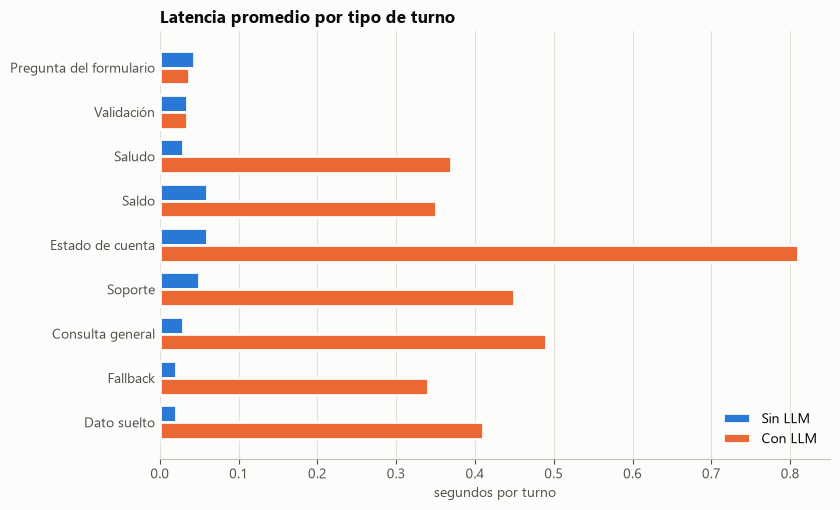

Versión,Sin LLM,Con LLM
Etiqueta,,
Pregunta del formulario,0.04,0.04
Validación,0.04,0.04
Saludo,0.03,0.37
Saldo,0.06,0.35
Estado de cuenta,0.06,0.81
Soporte,0.05,0.45
Consulta general,0.03,0.49
Fallback,0.02,0.34
Dato suelto,0.02,0.41


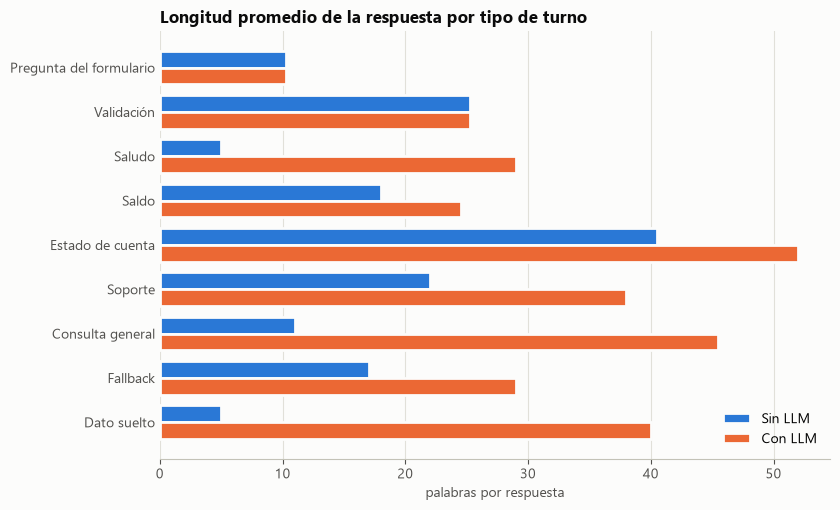

Versión,Sin LLM,Con LLM
Etiqueta,,
Pregunta del formulario,10.29,10.29
Validación,25.25,25.25
Saludo,5.00,29.00
Saldo,18.00,24.57
Estado de cuenta,40.50,52.00
Soporte,22.00,38.00
Consulta general,11.00,45.50
Fallback,17.00,29.00
Dato suelto,5.00,40.00


In [21]:
# === Figuras: latencia y longitud de respuesta por tipo de turno ===
ORDEN = ["Pregunta del formulario", "Validación", "Saludo", "Saldo", "Estado de cuenta",
         "Soporte", "Consulta general", "Fallback", "Dato suelto"]
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titlecolor": "#0b0b0b",
})


def barras_por_etiqueta(columna, titulo, xlabel, archivo):
    datos = conv_df.groupby(["Etiqueta", "Versión"])[columna].mean().unstack()
    datos = datos.reindex([e for e in ORDEN if e in datos.index])[list(PROYECTOS)]
    fig, ax = plt.subplots(figsize=(8.5, 5.2), facecolor="#fcfcfb")
    ax.set_facecolor("#fcfcfb")
    alto = 0.38
    posiciones = range(len(datos))
    for j, version in enumerate(datos.columns):
        ax.barh([y + (j - 0.5) * alto for y in posiciones], datos[version], height=alto,
                color=COLOR_VERSION[version], edgecolor="#fcfcfb", linewidth=2, label=version)
    ax.set_yticks(list(posiciones), datos.index)
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.set_title(titulo, loc="left", fontsize=12, fontweight="bold")
    ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    for lado in ("top", "right", "left"):
        ax.spines[lado].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.legend(frameon=False, loc="lower right")
    fig.tight_layout()
    fig.savefig(RESULTADOS / archivo, dpi=200, facecolor=fig.get_facecolor())
    plt.show()
    return datos.round(2)


tabla_latencia = barras_por_etiqueta("Latencia (s)", "Latencia promedio por tipo de turno",
                                     "segundos por turno", "latencia_por_tipo.png")
display(tabla_latencia)
tabla_palabras = barras_por_etiqueta("Palabras", "Longitud promedio de la respuesta por tipo de turno",
                                     "palabras por respuesta", "palabras_por_tipo.png")
display(tabla_palabras)

## 10. Fase 4 — Pruebas comparativas con las entradas de la actividad

Se ejecutan ambos sistemas con las cinco entradas que pide la actividad. Cada entrada se envía como **primer mensaje de una conversación nueva** y se repite **5 veces**, para medir qué tan consistente es cada sistema.

Cuando el bot responde con una pregunta de formulario (número de cliente, tipo de cuenta, periodo o tipo de problema), la prueba contesta automáticamente con los mismos valores en ambas versiones (`U001`, `débito`, `septiembre 2026` y una descripción del problema) hasta llegar a la respuesta final. Así se comparan tanto la **primera respuesta** como la **respuesta final**. Al medir la consistencia, el folio de soporte (`SOP-XXXXXX`) se enmascara: es aleatorio por diseño y no debe contar como una respuesta distinta.

In [22]:
# === Fase 4: entradas, respuestas automáticas a los formularios y ejecución ===
ENTRADAS_FASE4 = [
    "Hola",
    "Dame mi saldo bancario",
    "Quiero mi estado de cuenta",
    "Necesito ayuda con mi cuenta",
    "No puedo entrar a la aplicación",
]
REPETICIONES = 5

# Datos que deben aparecer en la respuesta final (cliente U001, cuenta de débito)
ESPERADO_FASE4 = {
    "Dame mi saldo bancario": ["20,500.75"],
    "Quiero mi estado de cuenta": ["16,000.00", "20,500.75"],
    "Necesito ayuda con mi cuenta": ["SOP-"],
    "No puedo entrar a la aplicación": ["SOP-"],
}

# Las preguntas de los formularios son textos fijos en ambas versiones (utter_ask_*)
PREGUNTAS = {k: v[0]["text"] for k, v in dominio_sin["responses"].items() if k.startswith("utter_ask_")}
RESPUESTA_AUTO = {
    "utter_ask_usuario_id": "U001",
    "utter_ask_tipo_cuenta": "débito",
    "utter_ask_fecha": "septiembre 2026",
}


def dato_pedido(texto, entrada):
    for clave, pregunta in PREGUNTAS.items():
        if pregunta in texto:
            if clave == "utter_ask_tipo_solicitud":
                return ("no puedo iniciar sesión en la aplicación" if "aplicación" in entrada.lower()
                        else "tengo un cargo no reconocido en mi cuenta")
            return RESPUESTA_AUTO[clave]
    return None


filas = []
for nombre, p in PROYECTOS.items():
    for entrada in ENTRADAS_FASE4:
        for rep in range(1, REPETICIONES + 1):
            sender = f"f4-{uuid.uuid4().hex[:8]}"
            mensaje, turno = entrada, 0
            while mensaje and turno < 6:
                turno += 1
                respuesta, latencia = enviar(p, sender, mensaje)
                texto = "\n".join(m.get("text", "") for m in respuesta if m.get("text"))
                filas.append({
                    "Versión": nombre, "Entrada": entrada, "Repetición": rep, "Turno": turno,
                    "Usuario": mensaje, "Respuesta": texto,
                    "Botones": ", ".join(b["title"] for m in respuesta for b in m.get("buttons", [])),
                    "Latencia (s)": round(latencia, 2), "Palabras": len(texto.split()),
                    "Cliente identificado": cliente_identificado(p, sender),
                })
                mensaje = dato_pedido(texto, entrada)

fase4 = pd.DataFrame(filas)
fase4 = pd.concat([fase4, fase4.apply(revisar, axis=1)], axis=1)

# Intención detectada para cada entrada (NLU, determinista)
intenciones_f4 = pd.DataFrame([
    {"Entrada": e, "Versión": v, "Intención": f"{analizar(p, e)[0]} ({analizar(p, e)[1]:.2f})"}
    for v, p in PROYECTOS.items() for e in ENTRADAS_FASE4
]).pivot(index="Entrada", columns="Versión", values="Intención").loc[ENTRADAS_FASE4][list(PROYECTOS)]
display(Markdown("**Intención detectada (confianza)**"))
display(intenciones_f4)
print(f"{len(fase4)} turnos ejecutados en total")

**Intención detectada (confianza)**

Versión,Sin LLM,Con LLM
Entrada,,
Hola,saludo (1.00),saludo (1.00)
Dame mi saldo bancario,consulta_saldo (1.00),consulta_saldo (1.00)
Quiero mi estado de cuenta,estado_cuenta (1.00),estado_cuenta (1.00)
Necesito ayuda con mi cuenta,soporte (1.00),soporte (1.00)
No puedo entrar a la aplicación,consulta_general (0.92),nlu_fallback (0.60)


110 turnos ejecutados en total


In [23]:
# === Fase 4: primera respuesta y respuesta final (repetición 1), lado a lado ===
rep1 = fase4[fase4["Repetición"] == 1]
primera = rep1[rep1["Turno"] == 1]
final = rep1.loc[rep1.groupby(["Versión", "Entrada"])["Turno"].idxmax()]


def lado_a_lado(df, titulo):
    filas = ""
    for entrada in ENTRADAS_FASE4:
        celdas = ""
        for v in PROYECTOS:
            f = df[(df["Versión"] == v) & (df["Entrada"] == entrada)].iloc[0]
            texto = html.escape(f["Respuesta"]).replace("\n", "<br>")
            extra = f"<div class='botones'>Botones: {html.escape(f['Botones'])}</div>" if f["Botones"] else ""
            celdas += f"<td>{texto}{extra}<div class='meta'>turno {f['Turno']} · {f['Latencia (s)']:.2f} s</div></td>"
        filas += f"<tr><td class='usuario'>{html.escape(entrada)}</td>{celdas}</tr>"
    return (f"<h4>{titulo}</h4><table class='transcripcion'><tr><th>Entrada</th>"
            f"<th>Sin LLM</th><th>Con LLM</th></tr>{filas}</table>")


display(HTML(ESTILO + lado_a_lado(primera, "Primera respuesta a cada entrada")
             + lado_a_lado(final, "Respuesta final (después de contestar las preguntas del formulario)")))

Entrada,Sin LLM,Con LLM
Hola,"Hola, ¿en qué puedo ayudarte?turno 1 · 0.02 s",¡Hola! Me alegra poder ayudarte. Mi nombre es Asistente Virtual del Banco. ¿En qué puedo ayudarte hoy?turno 1 · 0.29 s
Dame mi saldo bancario,"Para continuar, indícame tu número de cliente (por ejemplo, U001).turno 1 · 0.05 s","Para continuar, indícame tu número de cliente (por ejemplo, U001).turno 1 · 0.05 s"
Quiero mi estado de cuenta,"Para continuar, indícame tu número de cliente (por ejemplo, U001).turno 1 · 0.05 s","Para continuar, indícame tu número de cliente (por ejemplo, U001).turno 1 · 0.04 s"
Necesito ayuda con mi cuenta,¿Qué tipo de problema necesitas reportar?turno 1 · 0.02 s,¿Qué tipo de problema necesitas reportar?turno 1 · 0.02 s
No puedo entrar a la aplicación,"Claro. Puedo brindarte información sobre horarios, cuentas, sucursales y servicios bancarios.turno 1 · 0.01 s","Lo siento, no entendí tu consulta. ¿Podrías reformular tu pregunta y decirme cómo puedo ayudarte? Estamos aquí para ayudarte con cualquier pregunta o problema relacionado con tu cuenta bancaria. Puedes elegir entre las opciones disponibles: Consultar saldo, Estado de cuenta, Reportar un problema o Información general. ¿En qué puedo ayudarte hoy?Botones: Consultar saldo, Estado de cuenta, Reportar un problema, Información generalturno 1 · 0.54 s"
Entrada,Sin LLM,Con LLM
Hola,"Hola, ¿en qué puedo ayudarte?turno 1 · 0.02 s",¡Hola! Me alegra poder ayudarte. Mi nombre es Asistente Virtual del Banco. ¿En qué puedo ayudarte hoy?turno 1 · 0.29 s
Dame mi saldo bancario,"Ana López, el saldo disponible de tu cuenta de débito es de $20,500.75 MXN.turno 3 · 0.06 s","Hola Ana, el saldo disponible de tu cuenta de débito es de $20,500.75 MXN.turno 3 · 0.25 s"
Quiero mi estado de cuenta,"Estado de cuenta - Septiembre 2026Cliente: Ana LópezCuenta: debitoSaldo inicial: $16,000.00 MXNSaldo final: $20,500.75 MXNMovimientos:• 2026-09-01 - Depósito de nómina: $6,000.00 MXN• 2026-09-08 - Supermercado: $-1,250.25 MXN• 2026-09-15 - Transferencia SPEI: $-249.00 MXNturno 4 · 0.06 s","Hola Ana López, te presento el estado de cuenta de tu cuenta de débito para el mes de septiembre 2026. Tu saldo inicial era de $16,000.00 MXN y tu saldo final es de $20,500.75 MXN. A continuación, te muestro los movimientos realizados durante ese mes:- 2026-09-01: Depósito de nómina: $6,000.00 MXN- 2026-09-08: Supermercado: $-1,250.25 MXN- 2026-09-15: Transferencia SPEI: $-249.00 MXNturno 4 · 0.84 s"
Necesito ayuda con mi cuenta,Registré tu reporte de soporte: cargo no reconocido. Tu folio es SOP-CDC2B7. Un asesor dará seguimiento a tu caso.turno 2 · 0.03 s,"¡Hola! Gracias por contactarnos. He registrado tu reporte de soporte con el folio SOP-5C3AFF, relacionado con un cargo no reconocido en tu cuenta. Un asesor de nuestro equipo se pondrá en contacto contigo pronto para seguir tu caso.turno 2 · 0.42 s"


In [24]:
# === Fase 4: consistencia entre las 5 repeticiones ===
# El folio de soporte es aleatorio por diseño; se enmascara para que no cuente como variación de la respuesta.
def sin_folio(textos):
    return textos.str.replace(r"SOP-[0-9A-F]{6}", "SOP-######", regex=True)


def similitud_media(textos):
    textos = list(textos)
    pares = [(a, b) for i, a in enumerate(textos) for b in textos[i + 1:]]
    if not pares:
        return 1.0
    return sum(difflib.SequenceMatcher(None, a, b).ratio() for a, b in pares) / len(pares)


def resumen_entrada(g):
    finales = g.loc[g.groupby("Repetición")["Turno"].idxmax()]
    primeras = g[g["Turno"] == 1]
    esperado = ESPERADO_FASE4.get(g.name[1], [])
    return pd.Series({
        "Turnos hasta la respuesta final": int(finales["Turno"].median()),
        "Primeras respuestas distintas": sin_folio(primeras["Respuesta"]).nunique(),
        "Respuestas finales distintas": sin_folio(finales["Respuesta"]).nunique(),
        "Similitud media de las finales": round(similitud_media(sin_folio(finales["Respuesta"])), 2),
        "Dato esperado en todas": all(all(d in r for d in esperado) for r in finales["Respuesta"]) if esperado else None,
        "Datos no respaldados": int(((finales["Cantidades sin respaldo"] != "") | (finales["Nombres sin respaldo"] != "")).sum()),
        "Palabras (final)": round(finales["Palabras"].mean(), 1),
        "Latencia final (s)": round(finales["Latencia (s)"].mean(), 2),
    })


consistencia = fase4.groupby(["Versión", "Entrada"], sort=False).apply(resumen_entrada, include_groups=False)
display(consistencia)

# Variantes de la versión con LLM para dos entradas
for entrada in ["Hola", "Dame mi saldo bancario"]:
    g = fase4[(fase4["Versión"] == "Con LLM") & (fase4["Entrada"] == entrada)]
    finales = g.loc[g.groupby("Repetición")["Turno"].idxmax()]
    display(Markdown(f"**Con LLM · «{entrada}» · respuesta final en cada repetición**"))
    display(finales[["Repetición", "Respuesta"]].set_index("Repetición"))

Turnos hasta la respuesta final  Primeras respuestas distintas  Respuestas finales distintas  Similitud media de las finales Dato esperado en todas  \
Versión Entrada                                                                                                                                                                                
Sin LLM Hola                                                         1.0                            1.0                           1.0                            1.00                    NaN   
        Dame mi saldo bancario                                       3.0                            1.0                           1.0                            1.00                   True   
        Quiero mi estado de cuenta                                   4.0                            1.0                           1.0                            1.00                   True   
        Necesito ayuda con mi cuenta                                 2.0                            1.0                           1.0                            1.00                   True   
        No puedo entrar a la aplicación                              1.0                            1.0                           1.0                            1.00                  False   
Con LLM Hola                                                         1.0                            5.0                           5.0                            0.45                    NaN   
        Dame mi saldo bancario                                       3.0                            1.0                           2.0                            0.98                   True   
        Quiero mi estado de cuenta                                   4.0                            1.0                           5.0                            0.62                   True   
        Necesito ayuda con mi cuenta                                 2.0                            1.0                           5.0                            0.43                   True   
        No puedo entrar a la aplicación                              1.0                            5.0                           5.0                            0.29                  False   

                                         Datos no respaldados  Palabras (final)  Latencia final (s)  
Versión Entrada                                                                                      
Sin LLM Hola                                              0.0               5.0                0.02  
        Dame mi saldo bancario                            0.0              14.0                0.05  
        Quiero mi estado de cuenta                        0.0              41.0                0.06  
        Necesito ayuda con mi cuenta                      0.0              19.0                0.04  
        No puedo entrar a la aplicación                   0.0              11.0                0.02  
Con LLM Hola                                              1.0              26.4                0.32  
        Dame mi saldo bancario                            0.0              14.8                0.23  
        Quiero mi estado de cuenta                        0.0              57.4                0.81  
        Necesito ayuda con mi cuenta                      0.0              43.4                0.45  
        No puedo entrar a la aplicación                   1.0              48.0                0.47

**Con LLM · «Hola» · respuesta final en cada repetición**

,Respuesta
Repetición,
1,¡Hola! Me alegra poder ayudarte. Mi nombre es Asistente Virtual del Banco. ¿En qué puedo ayudarte hoy?
2,¡Hola! Me alegra que estés aquí. Mi nombre es Asistente Virtual del Banco y estoy aquí para ayudarte con cualquier c...
3,"¡Hola, ¿cómo estás? Me alegra que estés aquí. Mi nombre es Asistente Virtual del Banco y estoy aquí para ayudarte co..."
4,"¡Hola, Carlos! Bienvenido a nuestro banco. ¿En qué puedo ayudarte hoy?"
5,"¡Hola, ¿cómo estás? Me alegra que estés aquí. Puedo ayudarte con cualquier consulta o problema relacionado con tus s..."


**Con LLM · «Dame mi saldo bancario» · respuesta final en cada repetición**

,Respuesta
Repetición,
1,"Hola Ana, el saldo disponible de tu cuenta de débito es de $20,500.75 MXN."
2,"Hola Ana López, el saldo disponible de tu cuenta de débito es de $20,500.75 MXN."
3,"Hola Ana López, el saldo disponible de tu cuenta de débito es de $20,500.75 MXN."
4,"Hola Ana López, el saldo disponible de tu cuenta de débito es de $20,500.75 MXN."
5,"Hola Ana López, el saldo disponible de tu cuenta de débito es de $20,500.75 MXN."


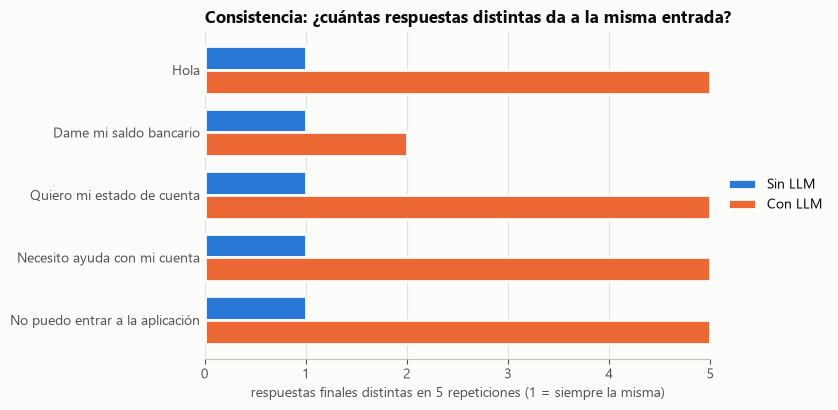

In [25]:
# === Figura: respuestas finales distintas en 5 repeticiones ===
datos = consistencia["Respuestas finales distintas"].unstack(0).loc[ENTRADAS_FASE4][list(PROYECTOS)]
fig, ax = plt.subplots(figsize=(8.5, 4.2), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
alto = 0.38
for j, version in enumerate(datos.columns):
    ax.barh([y + (j - 0.5) * alto for y in range(len(datos))], datos[version], height=alto,
            color=COLOR_VERSION[version], edgecolor="#fcfcfb", linewidth=2, label=version)
ax.set_yticks(range(len(datos)), datos.index)
ax.invert_yaxis()
ax.set_xlim(0, REPETICIONES)
ax.set_xticks(range(0, REPETICIONES + 1))
ax.set_xlabel(f"respuestas finales distintas en {REPETICIONES} repeticiones (1 = siempre la misma)")
ax.set_title("Consistencia: ¿cuántas respuestas distintas da a la misma entrada?", loc="left", fontsize=12, fontweight="bold")
ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for lado in ("top", "right", "left"):
    ax.spines[lado].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
fig.savefig(RESULTADOS / "fase4_consistencia.png", dpi=200, facecolor=fig.get_facecolor())
plt.show()

## 11. Fase 5 — Análisis del comportamiento

**¿Cuál sistema responde de forma más consistente?** El basado en reglas. Ante la misma entrada devuelve exactamente el mismo texto en todas las repeticiones (columna *Respuestas finales distintas* = 1). La versión con LLM conserva los **datos** —las cantidades salen del código y la columna *Dato esperado en todas* lo verifica—, pero puede **redactar distinto** cada vez.

**¿Cuál presenta mayor naturalidad?** El chatbot con LLM. Saluda y responde con frases completas, adapta el texto a la pregunta, usa el nombre del cliente cuando lo conoce y agrega cierres conversacionales. Las respuestas del sistema de reglas son correctas pero telegráficas, y en el estado de cuenta muestran el formato de una plantilla (`Cuenta: debito`).

**¿Ventajas de la generación de texto?** Responde preguntas abiertas con la información disponible sin escribir una respuesta por caso, personaliza con el contexto y varía la redacción. Además, la misma acción sirve para varias intenciones: solo se ajustan las instrucciones del prompt.

**¿Limitaciones de cada enfoque?**
- **Reglas:** rigidez. Cada respuesta nueva se escribe a mano y una respuesta genérica no contesta preguntas concretas.
- **LLM:** variabilidad, respuestas más largas y más lentas, dependencia de un servidor de modelo, riesgo de agregar información no respaldada (columna *Datos no respaldados* y sección de fidelidad) y riesgo de **omitir el dato principal** que el sistema ya calculó (escenarios no completados y columna *Dato esperado en todas*).
- **Ambos:** comparten el NLU. Si la intención se detecta mal o un formulario vuelve a preguntar algo que el usuario ya dijo, ni el texto fijo ni el LLM lo corrigen.

## 12. Conclusión (Fase 6)

- **Diferencias observadas.** Las dos versiones entienden lo mismo (mismo NLU), piden y validan los mismos datos y calculan las mismas cantidades. La diferencia está en la redacción. El sistema de reglas devuelve textos fijos o plantillas; el sistema con LLM genera el texto a partir de un prompt con la intención, la consulta, el contexto del cliente y los datos verificados.
- **Mayor consistencia:** el sistema basado en reglas, que da siempre la misma respuesta a la misma entrada. El sistema con LLM es consistente en los datos, pero no en la forma.
- **Respuestas más naturales:** el sistema con LLM. Usa frases completas, se adapta a la pregunta, se dirige al cliente por su nombre y aprovecha el historial reciente.
- **Ventajas de los modelos de lenguaje.** Contestan preguntas abiertas sin escribir una respuesta por caso, personalizan la conversación y facilitan extender el bot: se ajustan instrucciones y datos, no plantillas.
- **Limitaciones del chatbot con LLM.** Respuestas variables, más largas y unas diez veces más lentas (décimas de segundo en esta máquina con `127.0.0.1`; en Windows, `localhost` agrega ~2 s por conexión). Además, depende de Ollama y conserva el riesgo de agregar información no respaldada (un nombre de cliente inventado) o de omitir el dato principal que el sistema ya había calculado (un saldo o un folio).
- **Cuándo usar cada enfoque.** Reglas, para lo que debe ser exacto, auditable y rápido: confirmaciones, saldos, avisos legales y validaciones. LLM, para preguntas abiertas, explicaciones y conversaciones donde la naturalidad aporta valor. En un banco, lo recomendable es un **enfoque híbrido**: Rasa controla el flujo, los formularios y los datos, y el LLM solo redacta a partir de datos verificados, con un texto de respaldo si falla.

El análisis completo está en el reporte `Actividad_3_Reporte.pdf`.

In [26]:
# === Guardar resultados para el reporte ===
nlu_df.to_csv(RESULTADOS / "nlu_resultados.csv", index=False, encoding="utf-8-sig")
conv_df.to_csv(RESULTADOS / "conversaciones.csv", index=False, encoding="utf-8-sig")
evaluacion.to_csv(RESULTADOS / "escenarios.csv", index=False, encoding="utf-8-sig")
comparacion.to_csv(RESULTADOS / "comparacion.csv", encoding="utf-8-sig")
tabla_latencia.to_csv(RESULTADOS / "latencia_por_tipo.csv", encoding="utf-8-sig")
tabla_palabras.to_csv(RESULTADOS / "palabras_por_tipo.csv", encoding="utf-8-sig")
(RESULTADOS / "nlu_resumen.json").write_text(nlu_resumen.to_json(force_ascii=False, indent=2), encoding="utf-8")
(RESULTADOS / "contexto.json").write_text(contexto.to_json(force_ascii=False, indent=2), encoding="utf-8")
(RESULTADOS / "fidelidad.json").write_text(fidelidad.to_json(force_ascii=False, indent=2), encoding="utf-8")
fase4.to_csv(RESULTADOS / "fase4_turnos.csv", index=False, encoding="utf-8-sig")
consistencia.to_csv(RESULTADOS / "fase4_consistencia.csv", encoding="utf-8-sig")
intenciones_f4.to_csv(RESULTADOS / "fase4_intenciones.csv", encoding="utf-8-sig")

print("Archivos en", RESULTADOS.relative_to(BASE))
for f in sorted(RESULTADOS.iterdir()):
    print(" -", f.name)

Archivos en resultados
 - comparacion.csv
 - contexto.json
 - conversaciones.csv
 - escenarios.csv
 - fase4_consistencia.csv
 - fase4_consistencia.png
 - fase4_intenciones.csv
 - fase4_turnos.csv
 - fidelidad.json
 - latencia_por_tipo.csv
 - latencia_por_tipo.png
 - nlu_resultados.csv
 - nlu_resumen.json
 - palabras_por_tipo.csv
 - palabras_por_tipo.png


In [27]:
# === Detener los servidores ===
detener_todo()
print("Servidores detenidos.")

Servidores detenidos.
